# Combining B_036, B_039, B_042, F_001 and F_002 
using numpyro MCMC inference instead of pyros VI

In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import diffrax as dfx

# jax.config.update("jax_disable_jit",True)
jax.local_device_count()

import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import xarray
import ICIW_Plots
import tqdm

plt.style.use("ICIWstyle")
plt.rcParams.update(
    {
        "figure.dpi": 600,
        "font.size": 7,
        # "axes.linewidth": 0.8,
        # "axes.spines.top": False,
        # "axes.spines.right": False,
        # "axes.grid": False,
        # "legend.frameon": False,
    }
)

In [2]:
%config InlineBackend.print_figure_kwargs = {'bbox_inches':None}


In [3]:
from HSA_Cam_B_039_numpyro import kl_divergence_between_models
from HSA_Mo_B_011_numpyro import (
    kinetics_model,
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    validate_against_holdout,
    sample_prior,
    TRUE_PARAMS,
)

In [4]:
ov = [
    {
        "ID": "B_036",
        "run_name": "chivalrous-infographic",
        "dir": Path("data/chivalrous-infographic"),
        "DOE": "Koschany DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
    },
    {
        "ID": "B_039",
        "run_name": "agitated-health",
        "dir": Path("data/agitated-health"),
        "DOE": "paramEKLD DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
    },
    {
        "ID": "B_042",
        "run_name": "eternal-rock",
        "dir": Path("data/eternal-rock"),
        "DOE": "predEKLD DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
    },
    {
        "ID": "F_001",
        "run_name": "aquatic-value",
        "dir": Path("data/aquatic-value"),
        "DOE": "LHS32 DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
    },
    {
        "ID": "F_002",
        "run_name": "personal-anesthesia",
        "dir": Path("data/personal-anesthesia"),
        "DOE": "LHS64 DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
    },
]

In [5]:
def load_files(ov_dict):
    sum_file = ov_dict["dir"] / f"experiment_summary_{ov_dict['run_name']}.json"
    trace_files = sorted(ov_dict["dir"].glob(f"trace_*.nc"))
    test_data = xarray.open_dataset(ov_dict["holdout_data"])
    idatas = []
    valdatas = []
    paramEKLDS = []
    paramEKLDS_to_prior = []
    for i, trace_file in enumerate(tqdm.tqdm(trace_files)):
        idata = az.from_netcdf(trace_file)
        if i == 0:
            idata.prior = sample_prior(4000).prior
            # idata.add_groups({"prior": sample_prior(4000).prior})
        else:
            idata.prior=idatas[i - 1].posterior
            # idata.add_groups({"prior": idatas[i - 1].posterior})
        idatas.append(idata)
        valdata = validate_against_holdout(
            idata,
            test_data,
            num_samples=5000,
        )
        paramEKLD = kl_divergence_between_models(
            idata_new=idata,
            idata_old=idata,
            key_new="posterior",
            key_old="prior",
            var_names=[
                "k0",
                "Ea_k",
                "A_oh",
                "dH_oh",
                "A_h2",
                "dH_h2",
                "A_mix",
                "dH_mix",
                "sigma_r",
            ],
        ).sum()
        paramEKLD_to_prior = kl_divergence_between_models(
            idata_new=idata,
            idata_old=idatas[0],
            key_new="posterior",
            key_old="prior",
            var_names=[
                "k0",
                "Ea_k",
                "A_oh",
                "dH_oh",
                "A_h2",
                "dH_h2",
                "A_mix",
                "dH_mix",
                "sigma_r",
            ],
        ).sum()
        paramEKLDS.append(paramEKLD)
        paramEKLDS_to_prior.append(paramEKLD_to_prior)
        valdatas.append(valdata)
    ov_dict["idatas"] = idatas
    ov_dict["valdatas"] = valdatas
    ov_dict["paramEKLDS"] = paramEKLDS
    ov_dict["paramEKLDS_to_prior"] = paramEKLDS_to_prior
    with open(sum_file, "r") as f:
        exp_summary = json.load(f)
    ov_dict["proposals"] = np.array(exp_summary["trials"][-1]["observed"]["x"])
    ov_dict["r_obs"] = np.array(exp_summary["trials"][-1]["observed"]["y"])

In [6]:
for ov_dict in ov:
    load_files(ov_dict)
    print(ov_dict["r_obs"])

100%|██████████| 64/64 [00:34<00:00,  1.88it/s]


[[1.95435732e-05]
 [3.54373697e-05]
 [5.83814908e-05]
 [1.48688458e-04]
 [2.49709483e-05]
 [4.49895051e-05]
 [6.36128025e-05]
 [2.09380232e-04]
 [2.38393695e-05]
 [4.30005275e-05]
 [6.38878337e-05]
 [1.93399159e-04]
 [2.84745274e-05]
 [4.83323929e-05]
 [7.36608490e-05]
 [2.14043102e-04]
 [2.45979027e-05]
 [4.17338633e-05]
 [5.92950746e-05]
 [1.97556350e-04]
 [1.81384457e-05]
 [2.87181301e-05]
 [4.45275036e-05]
 [1.51173095e-04]
 [1.82925924e-05]
 [3.71592614e-05]
 [4.87889629e-05]
 [1.44094593e-04]
 [7.83500298e-07]
 [3.02032095e-06]
 [1.03744815e-05]
 [7.59320926e-07]
 [2.54099814e-06]
 [1.07681271e-05]
 [7.41266831e-07]
 [2.48163246e-06]
 [1.01934893e-05]
 [6.99614986e-07]
 [2.27614646e-06]
 [8.37559219e-06]
 [2.88066240e-05]
 [5.31033875e-05]
 [8.57258347e-05]
 [2.33002123e-04]
 [2.62299018e-05]
 [3.93789378e-05]
 [7.76413872e-05]
 [2.18236280e-04]
 [1.94316872e-05]
 [2.98858668e-05]
 [5.47566779e-05]
 [1.36012939e-04]
 [2.60466149e-05]
 [5.11972612e-05]
 [7.74687942e-05]
 [1.809247

100%|██████████| 32/32 [00:16<00:00,  1.94it/s]


[[7.54950349e-07]
 [1.76078247e-04]
 [7.83488867e-05]
 [2.62141293e-06]
 [9.66572225e-06]
 [2.32854203e-04]
 [1.05826416e-07]
 [1.02931401e-04]
 [3.88796224e-07]
 [1.41701472e-04]
 [7.86922328e-07]
 [3.08492672e-05]
 [3.32577329e-04]
 [3.63180163e-07]
 [4.65235316e-05]
 [3.30496334e-07]
 [7.09769495e-07]
 [1.32725283e-04]
 [2.48478551e-04]
 [2.55892694e-04]
 [3.82377242e-04]
 [3.86072752e-05]
 [2.34228821e-04]
 [3.39429789e-07]
 [1.03550792e-06]
 [1.97061837e-07]
 [1.77745333e-05]
 [1.57478453e-07]
 [1.71668819e-06]
 [7.75841613e-07]
 [2.54212704e-04]
 [2.96302478e-05]]


100%|██████████| 32/32 [00:16<00:00,  1.92it/s]


[[7.75984347e-07]
 [9.54363713e-05]
 [1.09246980e-06]
 [4.44414109e-05]
 [8.67387644e-06]
 [4.03154758e-07]
 [3.67531291e-04]
 [2.62139074e-04]
 [4.48418717e-07]
 [1.00394172e-04]
 [4.50014659e-06]
 [3.23687040e-04]
 [5.69915528e-07]
 [4.34196554e-04]
 [2.88931682e-04]
 [1.91693289e-07]
 [1.12023247e-06]
 [5.86040244e-07]
 [3.74293195e-05]
 [2.45076255e-04]
 [9.61330784e-07]
 [2.55089399e-04]
 [3.77153119e-05]
 [1.89625018e-04]
 [3.96474661e-07]
 [1.63304547e-04]
 [5.78498486e-07]
 [1.56900896e-07]
 [5.11403698e-07]
 [4.95536486e-04]
 [4.63696815e-05]
 [1.26311534e-07]]


100%|██████████| 32/32 [00:15<00:00,  2.01it/s]


[[3.81113459e-05]
 [7.37716473e-05]
 [8.68912957e-06]
 [1.02201730e-05]
 [1.44896865e-06]
 [1.52057410e-05]
 [5.64233014e-05]
 [9.54784173e-06]
 [2.17090637e-04]
 [5.36283278e-06]
 [2.28936296e-05]
 [2.24520918e-05]
 [3.13773194e-06]
 [7.79199909e-05]
 [1.83877783e-05]
 [5.35895936e-07]
 [1.10106214e-06]
 [1.78809823e-05]
 [4.00435738e-06]
 [1.58181695e-06]
 [5.98147108e-06]
 [1.76831018e-05]
 [2.91417673e-05]
 [2.34937238e-06]
 [1.09163317e-04]
 [1.38932301e-04]
 [3.50620644e-06]
 [6.04518755e-05]
 [1.69515144e-04]
 [7.57238959e-05]
 [6.77816206e-05]
 [2.02228352e-06]]


100%|██████████| 64/64 [00:30<00:00,  2.12it/s]

[[8.69601990e-06]
 [1.13072965e-05]
 [6.31859348e-06]
 [9.31130853e-06]
 [5.81490667e-06]
 [2.67630603e-05]
 [4.22914236e-05]
 [1.83952608e-04]
 [4.79473465e-06]
 [1.16079311e-04]
 [1.05285962e-05]
 [9.55478463e-05]
 [1.46429365e-05]
 [5.62659170e-06]
 [1.38053598e-04]
 [5.48447460e-05]
 [6.79760706e-05]
 [4.51197366e-06]
 [3.51644030e-06]
 [1.22362712e-06]
 [1.00545170e-04]
 [2.58783148e-05]
 [1.17198920e-06]
 [1.26009809e-06]
 [8.00313501e-06]
 [1.07476058e-04]
 [1.14960596e-04]
 [9.37467703e-05]
 [1.61719345e-05]
 [3.93401860e-05]
 [1.47076367e-04]
 [1.10143765e-05]
 [1.81096766e-05]
 [5.07140248e-05]
 [3.18416307e-04]
 [1.51205325e-06]
 [7.89552068e-05]
 [8.64152753e-05]
 [2.38685661e-05]
 [7.09151607e-07]
 [8.49058415e-05]
 [1.83612228e-05]
 [1.58924759e-05]
 [3.29909344e-05]
 [4.95596578e-06]
 [1.77189554e-06]
 [7.28474447e-07]
 [9.39092934e-05]
 [3.34017204e-06]
 [3.54395816e-05]
 [3.38808900e-06]
 [2.44030480e-06]
 [9.02887280e-07]
 [3.13750861e-05]
 [2.12833314e-04]
 [1.879066

In [7]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[var_name].values
    pred = postdata.posterior_predictive[var_name].values
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=2)).squeeze()
    return rmse_vals


def calculate_RMSEs(ov_dict):
    ov_dict["RMSEs"] = None
    for valdata in ov_dict["valdatas"]:
        rmse_da = bRMSE(valdata, "r_pred")
        if ov_dict["RMSEs"] is None:
            ov_dict["RMSEs"] = [rmse_da]
        else:
            ov_dict["RMSEs"].append(rmse_da)
    ov_dict["RMSEs"] = np.array(ov_dict["RMSEs"])

In [8]:
for ov_dict in ov:
    calculate_RMSEs(ov_dict)

In [9]:
ov[0]["RMSEs"][-1].shape

(5000,)

In [10]:
print(ov[0]["RMSEs"][-1].mean())
print(az.hdi(ov[0]["RMSEs"][-1], prob=0.95))

2.984869978143519e-06
[8.10368819e-07 5.19781201e-06]


In [11]:
print(ov[1]["RMSEs"].mean(axis=1))
# print index where mean RMSE is less than 3e-6
indices = [i for i, rmse in enumerate(ov[1]["RMSEs"].mean(axis=1)) if rmse < 3e-6]
print(indices)
print(ov[1]["RMSEs"].mean(axis=1)[indices[0]])
print(az.hdi(ov[1]["RMSEs"][indices[0]], prob=0.95))

[2.12890860e-04 5.02260245e-05 2.18401058e-05 9.21064645e-06
 9.02873692e-06 4.91192198e-06 4.69212732e-06 3.68062028e-06
 3.53144930e-06 3.93013187e-06 3.73319460e-06 4.32296659e-06
 6.97406501e-06 7.03836091e-06 7.04859464e-06 6.92203995e-06
 6.79283215e-06 6.56595128e-06 4.09659208e-06 3.87513953e-06
 3.12997563e-06 3.28565529e-06 3.15509747e-06 3.09534378e-06
 2.99915265e-06 3.02396421e-06 3.15573708e-06 3.19901405e-06
 3.10035223e-06 3.06919491e-06 2.99855894e-06 2.98975384e-06]
[24, 30, 31]
2.999152653796294e-06
[5.40624598e-07 5.89050937e-06]


In [12]:
print(ov[2]["RMSEs"].mean(axis=1))
indices = [i for i, rmse in enumerate(ov[2]["RMSEs"].mean(axis=1)) if rmse < 3e-6]
print(indices)
print(ov[2]["RMSEs"].mean(axis=1)[indices[0]])
print(az.hdi(ov[2]["RMSEs"][indices[0]], prob=0.95))

[2.13256830e-04 1.85773348e-05 1.45030205e-05 1.05553539e-05
 9.16261831e-06 7.41198647e-06 5.90281282e-06 5.06488423e-06
 4.58257787e-06 4.41576615e-06 3.86449451e-06 4.22757078e-06
 4.45335670e-06 4.75716785e-06 4.02301938e-06 3.89368037e-06
 3.84886291e-06 3.85215561e-06 3.56425487e-06 3.68538497e-06
 3.66156226e-06 2.93541675e-06 3.03621924e-06 2.97662009e-06
 2.95635280e-06 3.17791656e-06 3.14831435e-06 3.23907564e-06
 3.18289516e-06 3.69077411e-06 3.74567582e-06 3.67320103e-06]
[21, 23, 24]
2.935416746528763e-06
[7.77078737e-07 5.79405717e-06]


## parameter values

In [13]:
import pandas as pd

pd.set_option("display.float_format", lambda x: "%.2e" % x)
for ov_dict in ov:
    print("=" * 40)
    print(f"Results for {ov_dict['ID']} - {ov_dict['DOE']}")
    print("-" * 40)
    sum = (
        az.summary(
            ov_dict["idatas"][-1],
            var_names=[
                "k0",
                "Ea_k",
                "A_oh",
                "dH_oh",
                "A_h2",
                "dH_h2",
                "A_mix",
                "dH_mix",
            ],
            round_to=14,
            fmt="wide",
        ),
    )
    sum[0].to_csv(f"{ov_dict['ID']}_parameter_summary.csv")
    print(sum[0])

Results for B_036 - Koschany DOE
----------------------------------------
            mean       sd  eti89_lb  eti89_ub  ess_bulk  ess_tail    r_hat  \
k0      3.20e-04 4.76e-05  2.54e-04  4.03e-04  1.47e+04  1.59e+04 1.00e+00   
Ea_k    7.68e+04 3.52e+03  7.11e+04  8.24e+04  2.05e+04  1.89e+04 1.00e+00   
A_oh    5.14e-01 7.02e-02  4.04e-01  6.28e-01  3.06e+04  2.03e+04 1.00e+00   
dH_oh   7.55e+03 6.43e+03  5.13e+02  1.97e+04  2.10e+04  1.34e+04 1.00e+00   
A_h2    3.64e-01 6.65e-02  2.66e-01  4.77e-01  1.40e+04  1.58e+04 1.00e+00   
dH_h2  -7.75e+03 4.02e+03 -1.41e+04 -1.24e+03  2.50e+04  2.17e+04 1.00e+00   
A_mix   8.67e-01 1.02e-01  7.17e-01  1.04e+00  1.67e+04  1.72e+04 1.00e+00   
dH_mix -1.01e+04 3.07e+03 -1.49e+04 -5.07e+03  2.38e+04  2.06e+04 1.00e+00   

        mcse_mean  mcse_sd  
k0       4.02e-07 3.50e-07  
Ea_k     2.46e+01 1.76e+01  
A_oh     4.00e-04 2.97e-04  
dH_oh    3.42e+01 3.55e+01  
A_h2     5.64e-04 4.38e-04  
dH_h2    2.54e+01 1.78e+01  
A_mix    8.00e-04 6.

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning:

Unscientific behavior. No xlabel provided.

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning:

Unscientific behavior. No ylabel provided.

/tmp/ipykernel_84390/2176105179.py:111: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



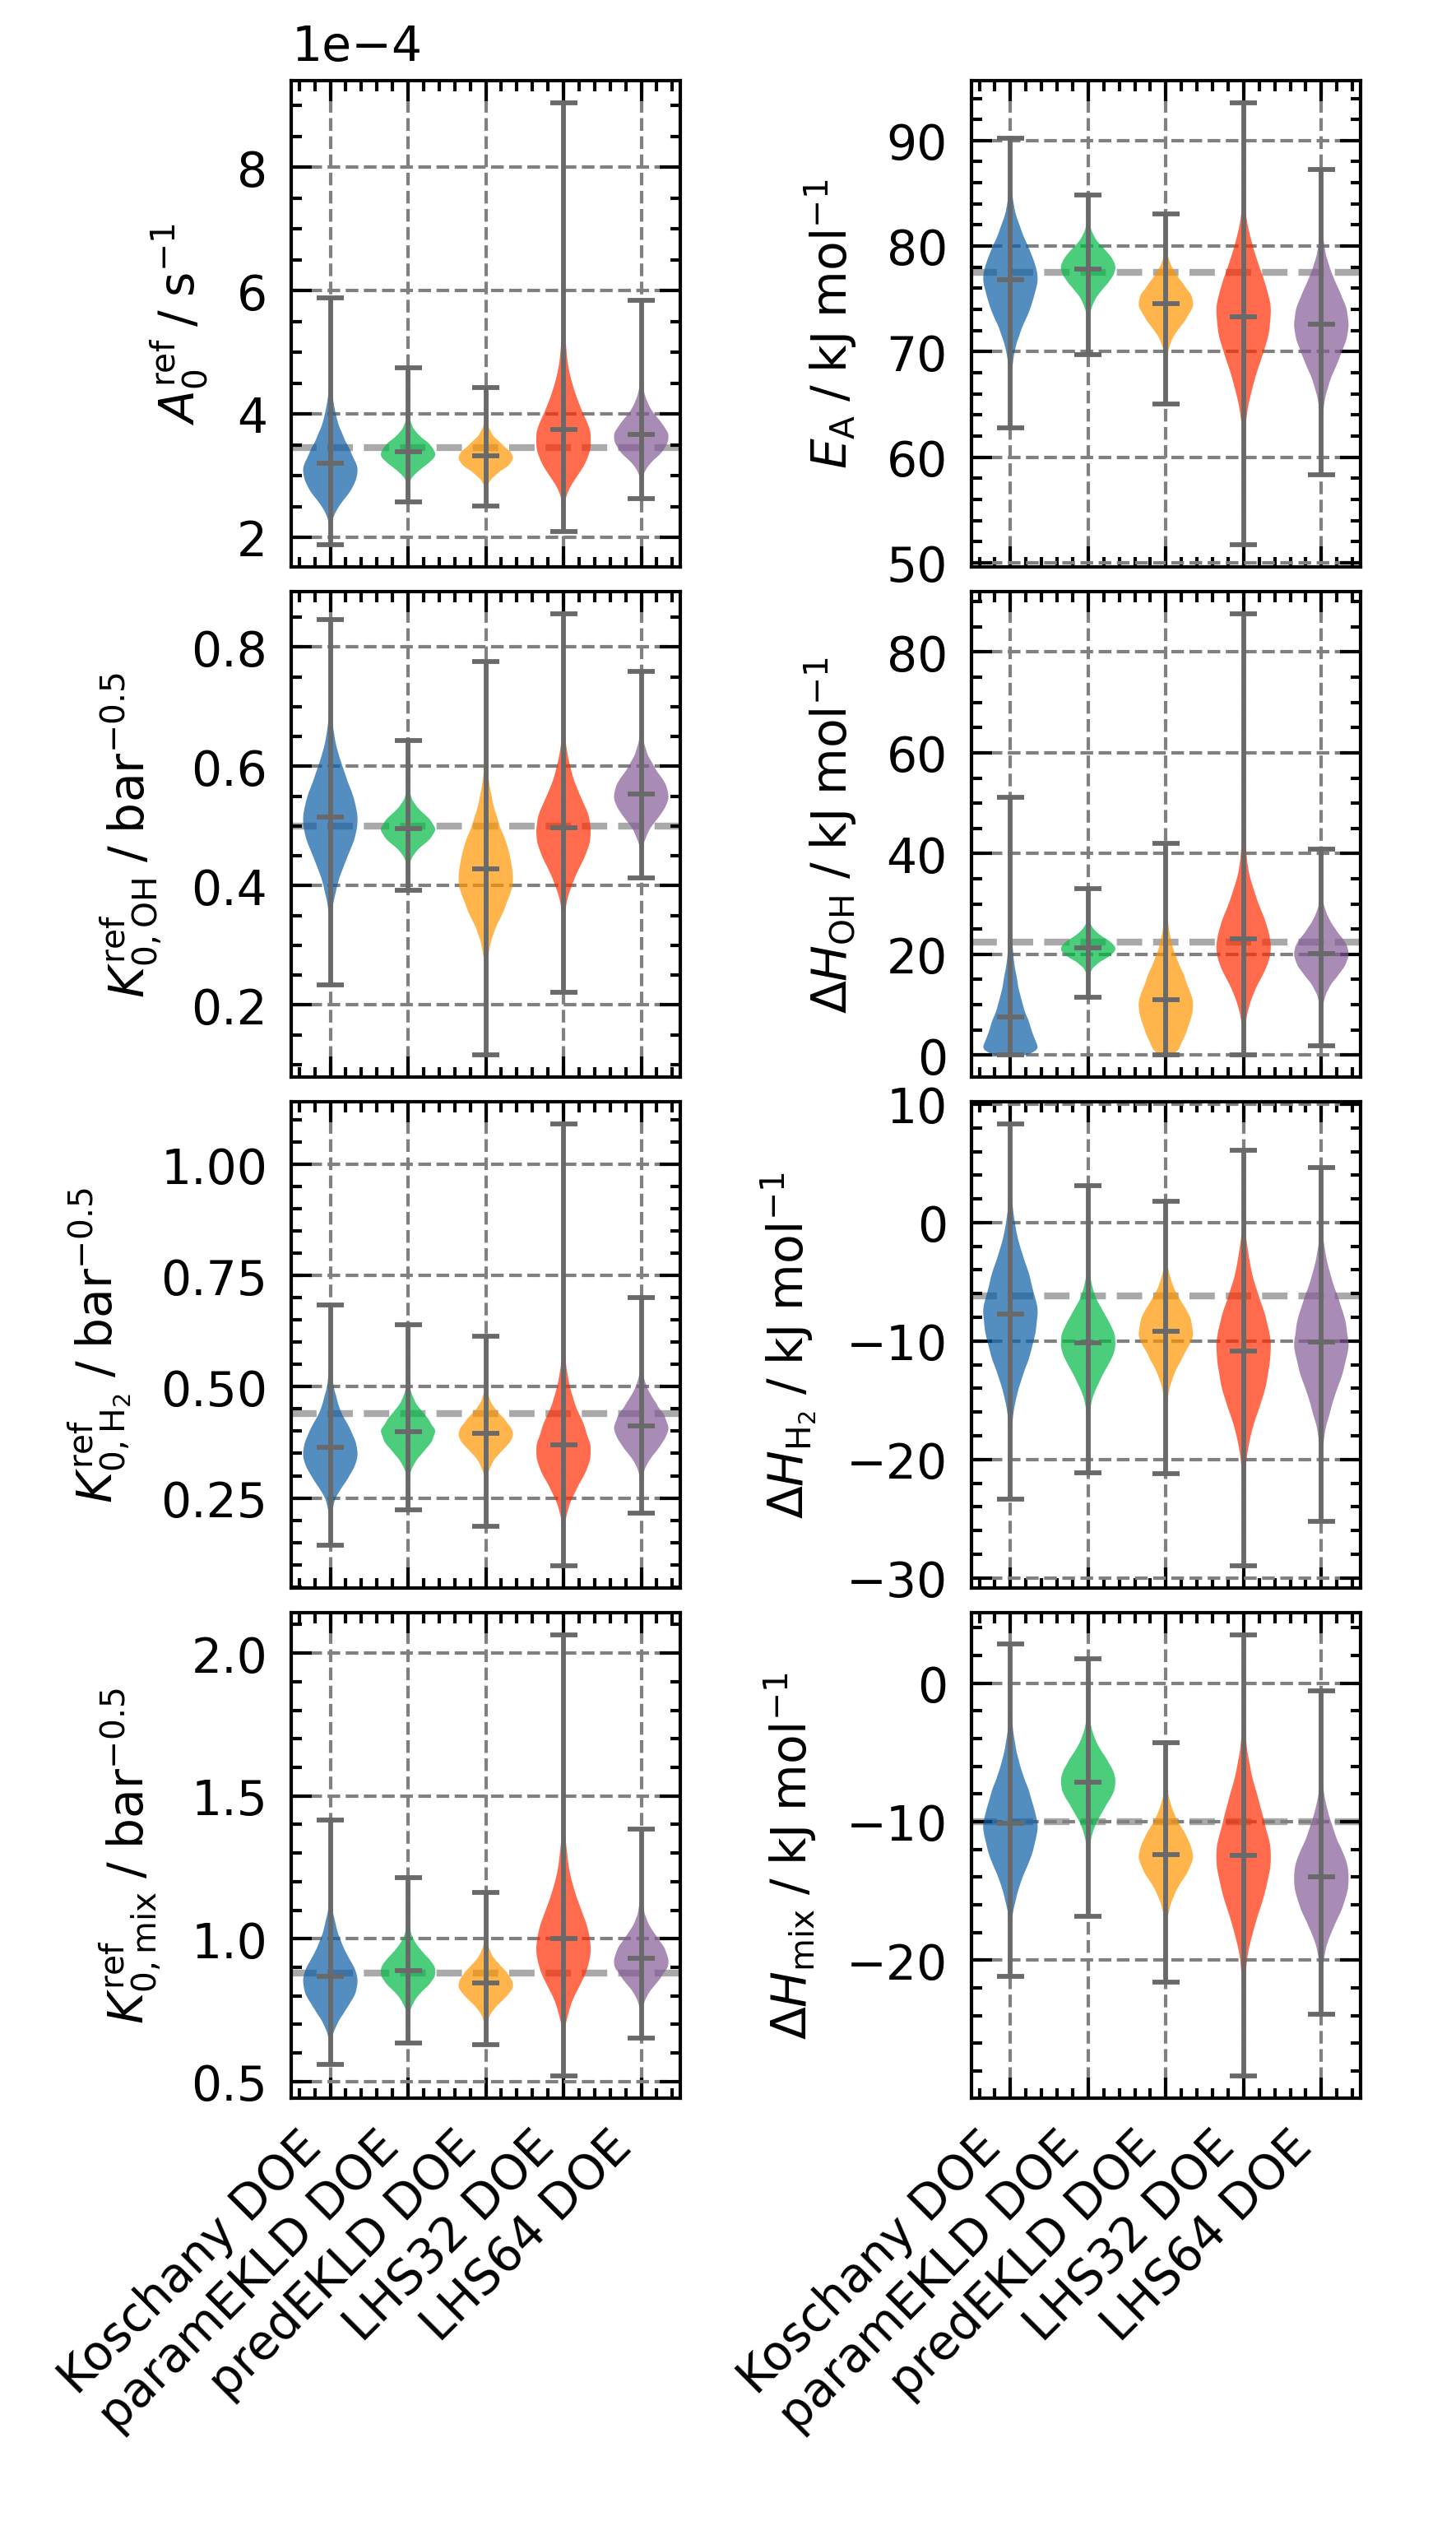

In [14]:
# fig, axes = plt.subplots(4, 2, figsize=(12, 16))
fig = ICIW_Plots.figure(layout="single_column", height=13 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.0 * ICIW_Plots.cm2inch,
    ax_layout=(4, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.5 * ICIW_Plots.cm2inch,
    # sharex=True,
    left_h=1.5 * ICIW_Plots.cm2inch,
    bottom_v=2.2 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()

param_names = ["k0", "Ea_k", "A_oh", "dH_oh", "A_h2", "dH_h2", "A_mix", "dH_mix"]

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}
labeldict = {
    "k0": r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$",
    "Ea_k": r"$E_\mathrm{A}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_oh": r"$K_{0,\mathrm{OH}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_oh": r"$\Delta H_\mathrm{OH}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_h2": r"$K_{0,\mathrm{H_2}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_h2": r"$\Delta H_\mathrm{H_2}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_mix": r"$K_{0,\mathrm{mix}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_mix": r"$\Delta H_\mathrm{mix}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
}

for idx, param in enumerate(param_names):
    ax = axes[idx]

    # Collect samples for each DOE method
    violin_data = []
    labels = []

    for i, ov_dict in enumerate(ov):
        # Get final posterior samples for this parameter
        samples = ov_dict["idatas"][-1].posterior[param].values.flatten()
        if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
            samples = samples * 1e-3  # Convert to kJ/mol for better readability
        violin_data.append(samples)
        labels.append(ov_dict["DOE"])

    # Create violin plot
    parts = ax.violinplot(
        violin_data,
        positions=range(len(ov)),
        showmeans=True,
        # showmedians=True,
        widths=0.7,
    )

    # Make violin lines thinner
    for partname in ("cbars", "cmins", "cmaxes", "cmeans", "cmedians"):
        if partname in parts:

            parts[partname].set_color("dimgrey")
            parts[partname].set_linewidth(0.7)

    # Color the violins
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for i, pc in enumerate(parts["bodies"]):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
        # pc.set_linewidth(1.0)

    # Plot ground truth
    true_val = TRUE_PARAMS[keydict[param]]
    if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
        true_val = true_val * 1e-3  # Convert to kJ/mol for better readability
    ax.axhline(
        y=true_val,
        color="darkgrey",
        linestyle="--",
        linewidth=1.0,
        label="Ground Truth",
        zorder=0,
    )

    ax.set_ylabel(f"{labeldict[param]}")
    ax.set_xticks(range(len(ov)))

    # Only show x-axis labels in the last row (indices 6 and 7)
    if idx >= 6:
        ax.set_xticklabels(
            [ov_dict["DOE"] for ov_dict in ov],
            rotation=45,
            ha="right",
        )
    else:
        ax.set_xticklabels([])

    # ax.grid(True, alpha=0.3)
    # ax.legend(loc="best")
    # ax.set_title(f"{keydict[param]}")

    # Adjust x-axis limits
    ax.set_xlim(-0.5, len(ov) - 0.5)

axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

plt.tight_layout()
# plt.savefig("figures/KinFit_parameter_comparison.png")
# plt.savefig("figures/KinFit_parameter_comparison.svg")
# plt.savefig("figures/KinFit_parameter_comparison.pdf")
plt.show()

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning:

Unscientific behavior. No xlabel provided.

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning:

Unscientific behavior. No ylabel provided.

/tmp/ipykernel_84390/391212938.py:120: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



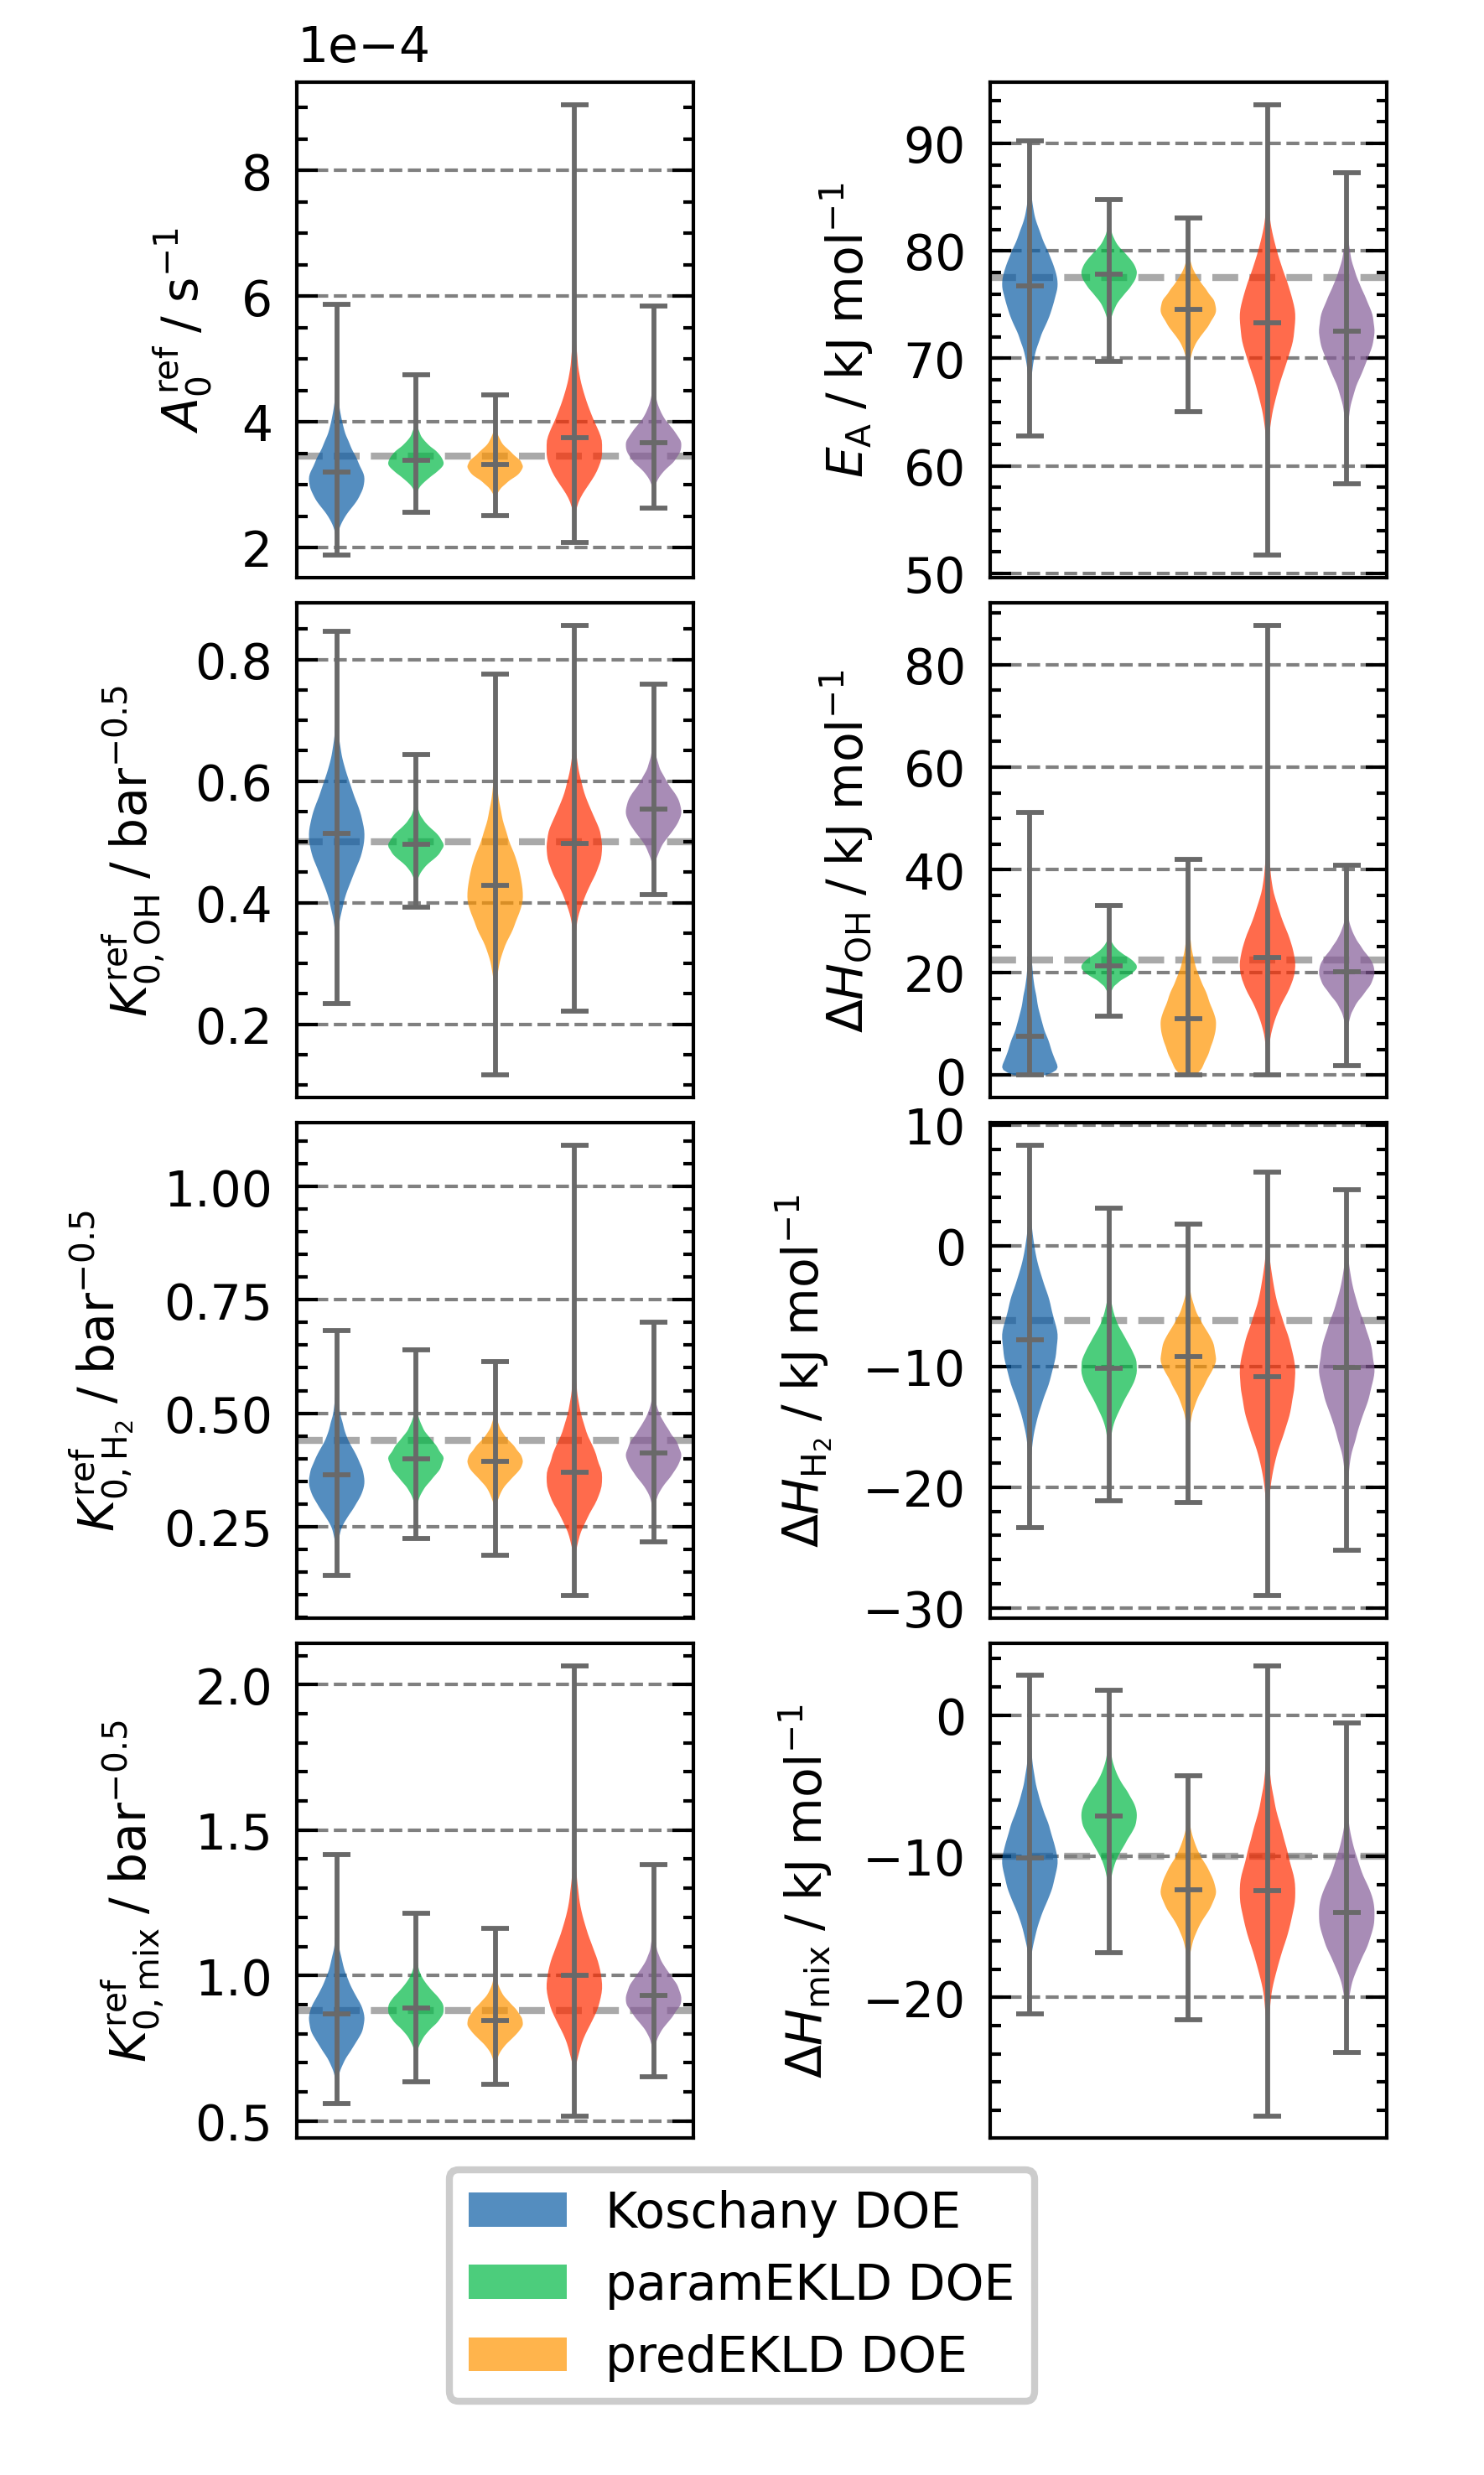

In [15]:
# fig, axes = plt.subplots(4, 2, figsize=(12, 16))
fig = ICIW_Plots.figure(layout="single_column", height=12.5 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.0 * ICIW_Plots.cm2inch,
    ax_layout=(4, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.5 * ICIW_Plots.cm2inch,
    # sharex=True,
    left_h=1.5 * ICIW_Plots.cm2inch,
    bottom_v=1.7 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()

param_names = ["k0", "Ea_k", "A_oh", "dH_oh", "A_h2", "dH_h2", "A_mix", "dH_mix"]

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}
labeldict = {
    "k0": r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$",
    "Ea_k": r"$E_\mathrm{A}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_oh": r"$K_{0,\mathrm{OH}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_oh": r"$\Delta H_\mathrm{OH}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_h2": r"$K_{0,\mathrm{H_2}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_h2": r"$\Delta H_\mathrm{H_2}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_mix": r"$K_{0,\mathrm{mix}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_mix": r"$\Delta H_\mathrm{mix}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
}

for idx, param in enumerate(param_names):
    ax = axes[idx]

    # Collect samples for each DOE method
    violin_data = []
    labels = []

    for i, ov_dict in enumerate(ov):
        # Get final posterior samples for this parameter
        samples = ov_dict["idatas"][-1].posterior[param].values.flatten()
        if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
            samples = samples * 1e-3  # Convert to kJ/mol for better readability
        violin_data.append(samples)
        labels.append(ov_dict["DOE"])

    # Create violin plot
    parts = ax.violinplot(
        violin_data,
        positions=range(len(ov)),
        showmeans=True,
        # showmedians=True,
        widths=0.7,
    )

    # Make violin lines thinner
    for partname in ("cbars", "cmins", "cmaxes", "cmeans", "cmedians"):
        if partname in parts:

            parts[partname].set_color("dimgrey")
            parts[partname].set_linewidth(0.7)

    # Color the violins
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for i, pc in enumerate(parts["bodies"]):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
        # pc.set_linewidth(1.0)

    # Plot ground truth
    true_val = TRUE_PARAMS[keydict[param]]
    if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
        true_val = true_val * 1e-3  # Convert to kJ/mol for better readability
    ax.axhline(
        y=true_val,
        color="darkgrey",
        linestyle="--",
        linewidth=1.0,
        label="Ground Truth",
        zorder=0,
    )

    ax.set_ylabel(f"{labeldict[param]}")

    # Remove x-axis ticks and labels
    ax.set_xticks([])
    ax.set_xticklabels([])

    # Remove x-axis grid
    ax.grid(False, axis="x")

    # Adjust x-axis limits
    ax.set_xlim(-0.5, len(ov) - 0.5)

axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

# Create legend with DOE methods centered beneath the plots
from matplotlib.patches import Patch

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
legend_elements = [
    Patch(facecolor=colors[0], alpha=0.7, label="Koschany DOE"),
    Patch(facecolor=colors[1], alpha=0.7, label="paramEKLD DOE"),
    Patch(facecolor=colors[2], alpha=0.7, label="predEKLD DOE"),
]
fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=1,
    frameon=True,
    bbox_to_anchor=(0.5, 0.02),
)

plt.tight_layout()
# plt.savefig("figures/KinFit_parameter_comparison.png")
# plt.savefig("figures/KinFit_parameter_comparison.svg")
# plt.savefig("figures/KinFit_parameter_comparison.pdf")
plt.show()

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning:

Unscientific behavior. No xlabel provided.

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning:

Unscientific behavior. No ylabel provided.

/tmp/ipykernel_84390/3041408562.py:120: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



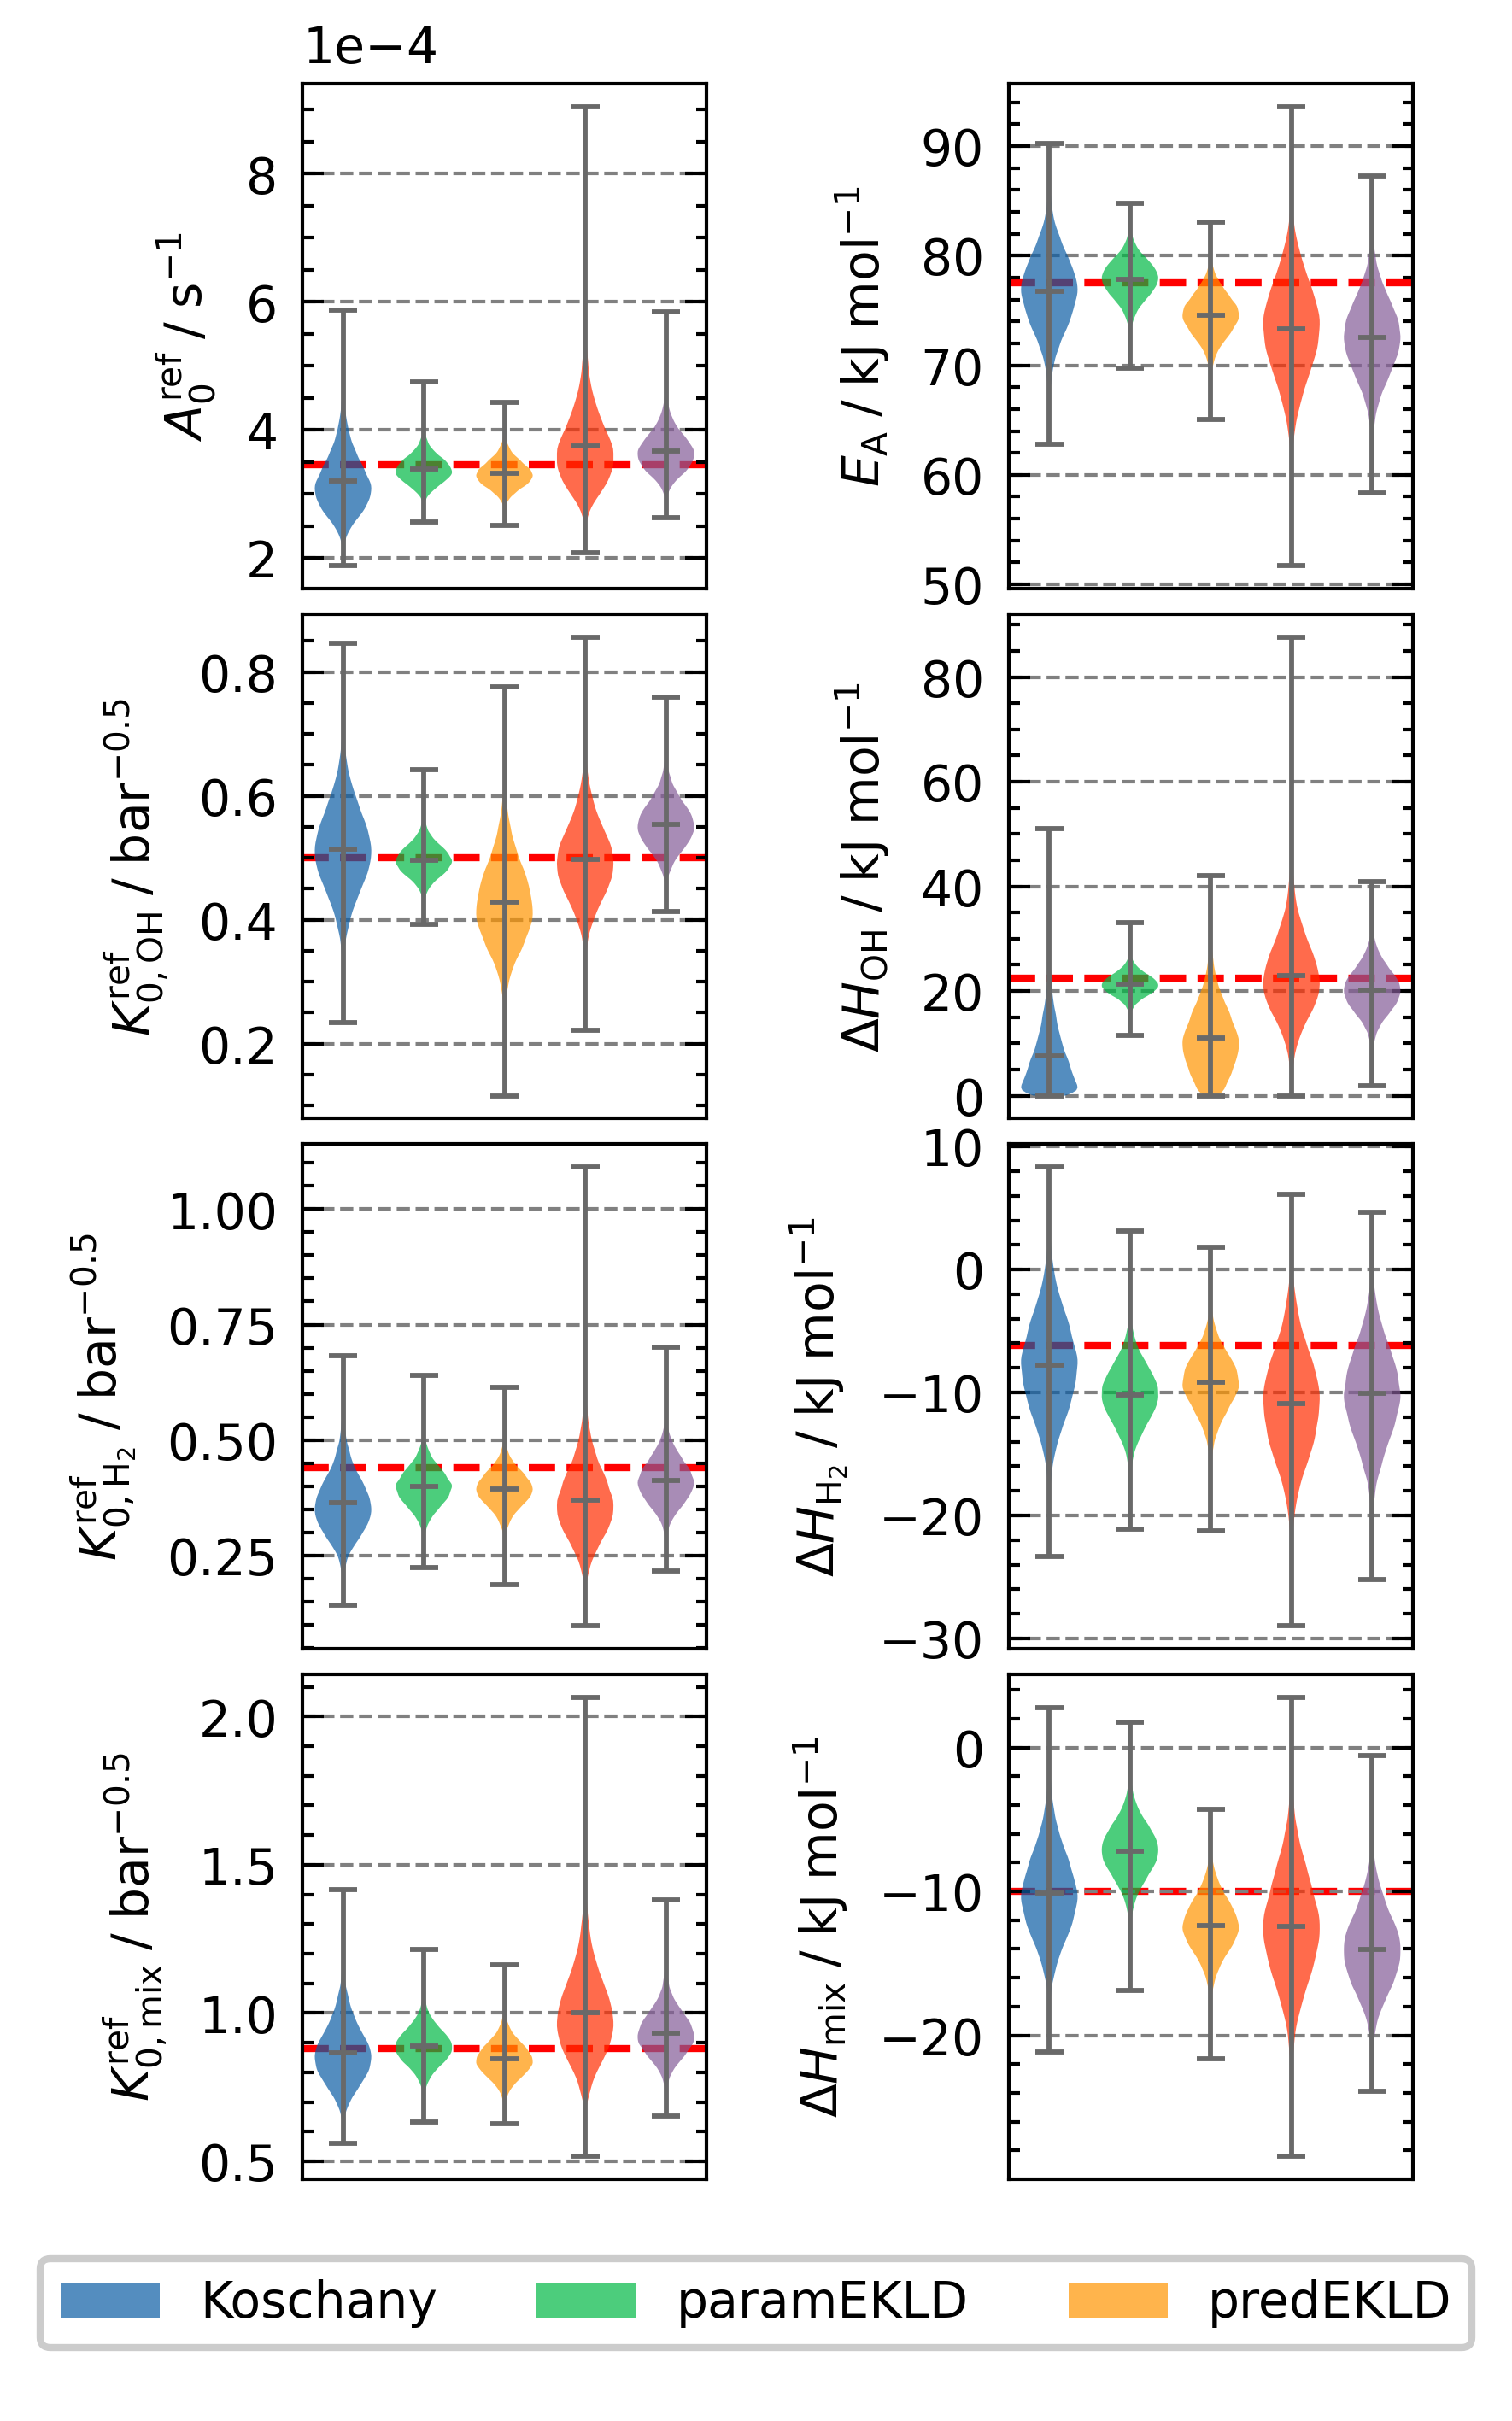

In [16]:
# fig, axes = plt.subplots(4, 2, figsize=(12, 16))
fig = ICIW_Plots.figure(layout="single_column", height=12 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.0 * ICIW_Plots.cm2inch,
    ax_layout=(4, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.5 * ICIW_Plots.cm2inch,
    # sharex=True,
    left_h=1.5 * ICIW_Plots.cm2inch,
    bottom_v=1.2 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()

param_names = ["k0", "Ea_k", "A_oh", "dH_oh", "A_h2", "dH_h2", "A_mix", "dH_mix"]

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}
labeldict = {
    "k0": r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$",
    "Ea_k": r"$E_\mathrm{A}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_oh": r"$K_{0,\mathrm{OH}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_oh": r"$\Delta H_\mathrm{OH}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_h2": r"$K_{0,\mathrm{H_2}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_h2": r"$\Delta H_\mathrm{H_2}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_mix": r"$K_{0,\mathrm{mix}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_mix": r"$\Delta H_\mathrm{mix}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
}

for idx, param in enumerate(param_names):
    ax = axes[idx]

    # Collect samples for each DOE method
    violin_data = []
    labels = []

    for i, ov_dict in enumerate(ov):
        # Get final posterior samples for this parameter
        samples = ov_dict["idatas"][-1].posterior[param].values.flatten()
        if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
            samples = samples * 1e-3  # Convert to kJ/mol for better readability
        violin_data.append(samples)
        labels.append(ov_dict["DOE"])

    # Create violin plot
    parts = ax.violinplot(
        violin_data,
        positions=range(len(ov)),
        showmeans=True,
        # showmedians=True,
        widths=0.7,
    )

    # Make violin lines thinner
    for partname in ("cbars", "cmins", "cmaxes", "cmeans", "cmedians"):
        if partname in parts:

            parts[partname].set_color("dimgrey")
            parts[partname].set_linewidth(0.7)

    # Color the violins
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for i, pc in enumerate(parts["bodies"]):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
        # pc.set_linewidth(1.0)

    # Plot ground truth
    true_val = TRUE_PARAMS[keydict[param]]
    if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
        true_val = true_val * 1e-3  # Convert to kJ/mol for better readability
    ax.axhline(
        y=true_val,
        color="red",
        linestyle="--",
        linewidth=1.0,
        label="Ground Truth",
        zorder=0,
    )

    ax.set_ylabel(f"{labeldict[param]}")

    # Remove x-axis ticks and labels
    ax.set_xticks([])
    ax.set_xticklabels([])

    # Remove x-axis grid
    ax.grid(False, axis="x")

    # Adjust x-axis limits
    ax.set_xlim(-0.5, len(ov) - 0.5)

axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

# Create legend with DOE methods centered beneath the plots
from matplotlib.patches import Patch

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
legend_elements = [
    Patch(facecolor=colors[0], alpha=0.7, label="Koschany"),
    Patch(facecolor=colors[1], alpha=0.7, label="paramEKLD"),
    Patch(facecolor=colors[2], alpha=0.7, label="predEKLD"),
]
fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    frameon=True,
    bbox_to_anchor=(0.5, 0.02),
)

plt.tight_layout()
# plt.savefig("figures/KinFit_parameter_comparison.png")
# plt.savefig("figures/KinFit_parameter_comparison.svg")
# plt.savefig("figures/KinFit_parameter_comparison.pdf")
plt.show()

### Predictive accuracy

Koschany DOE
paramEKLD DOE
predEKLD DOE
LHS32 DOE
LHS64 DOE


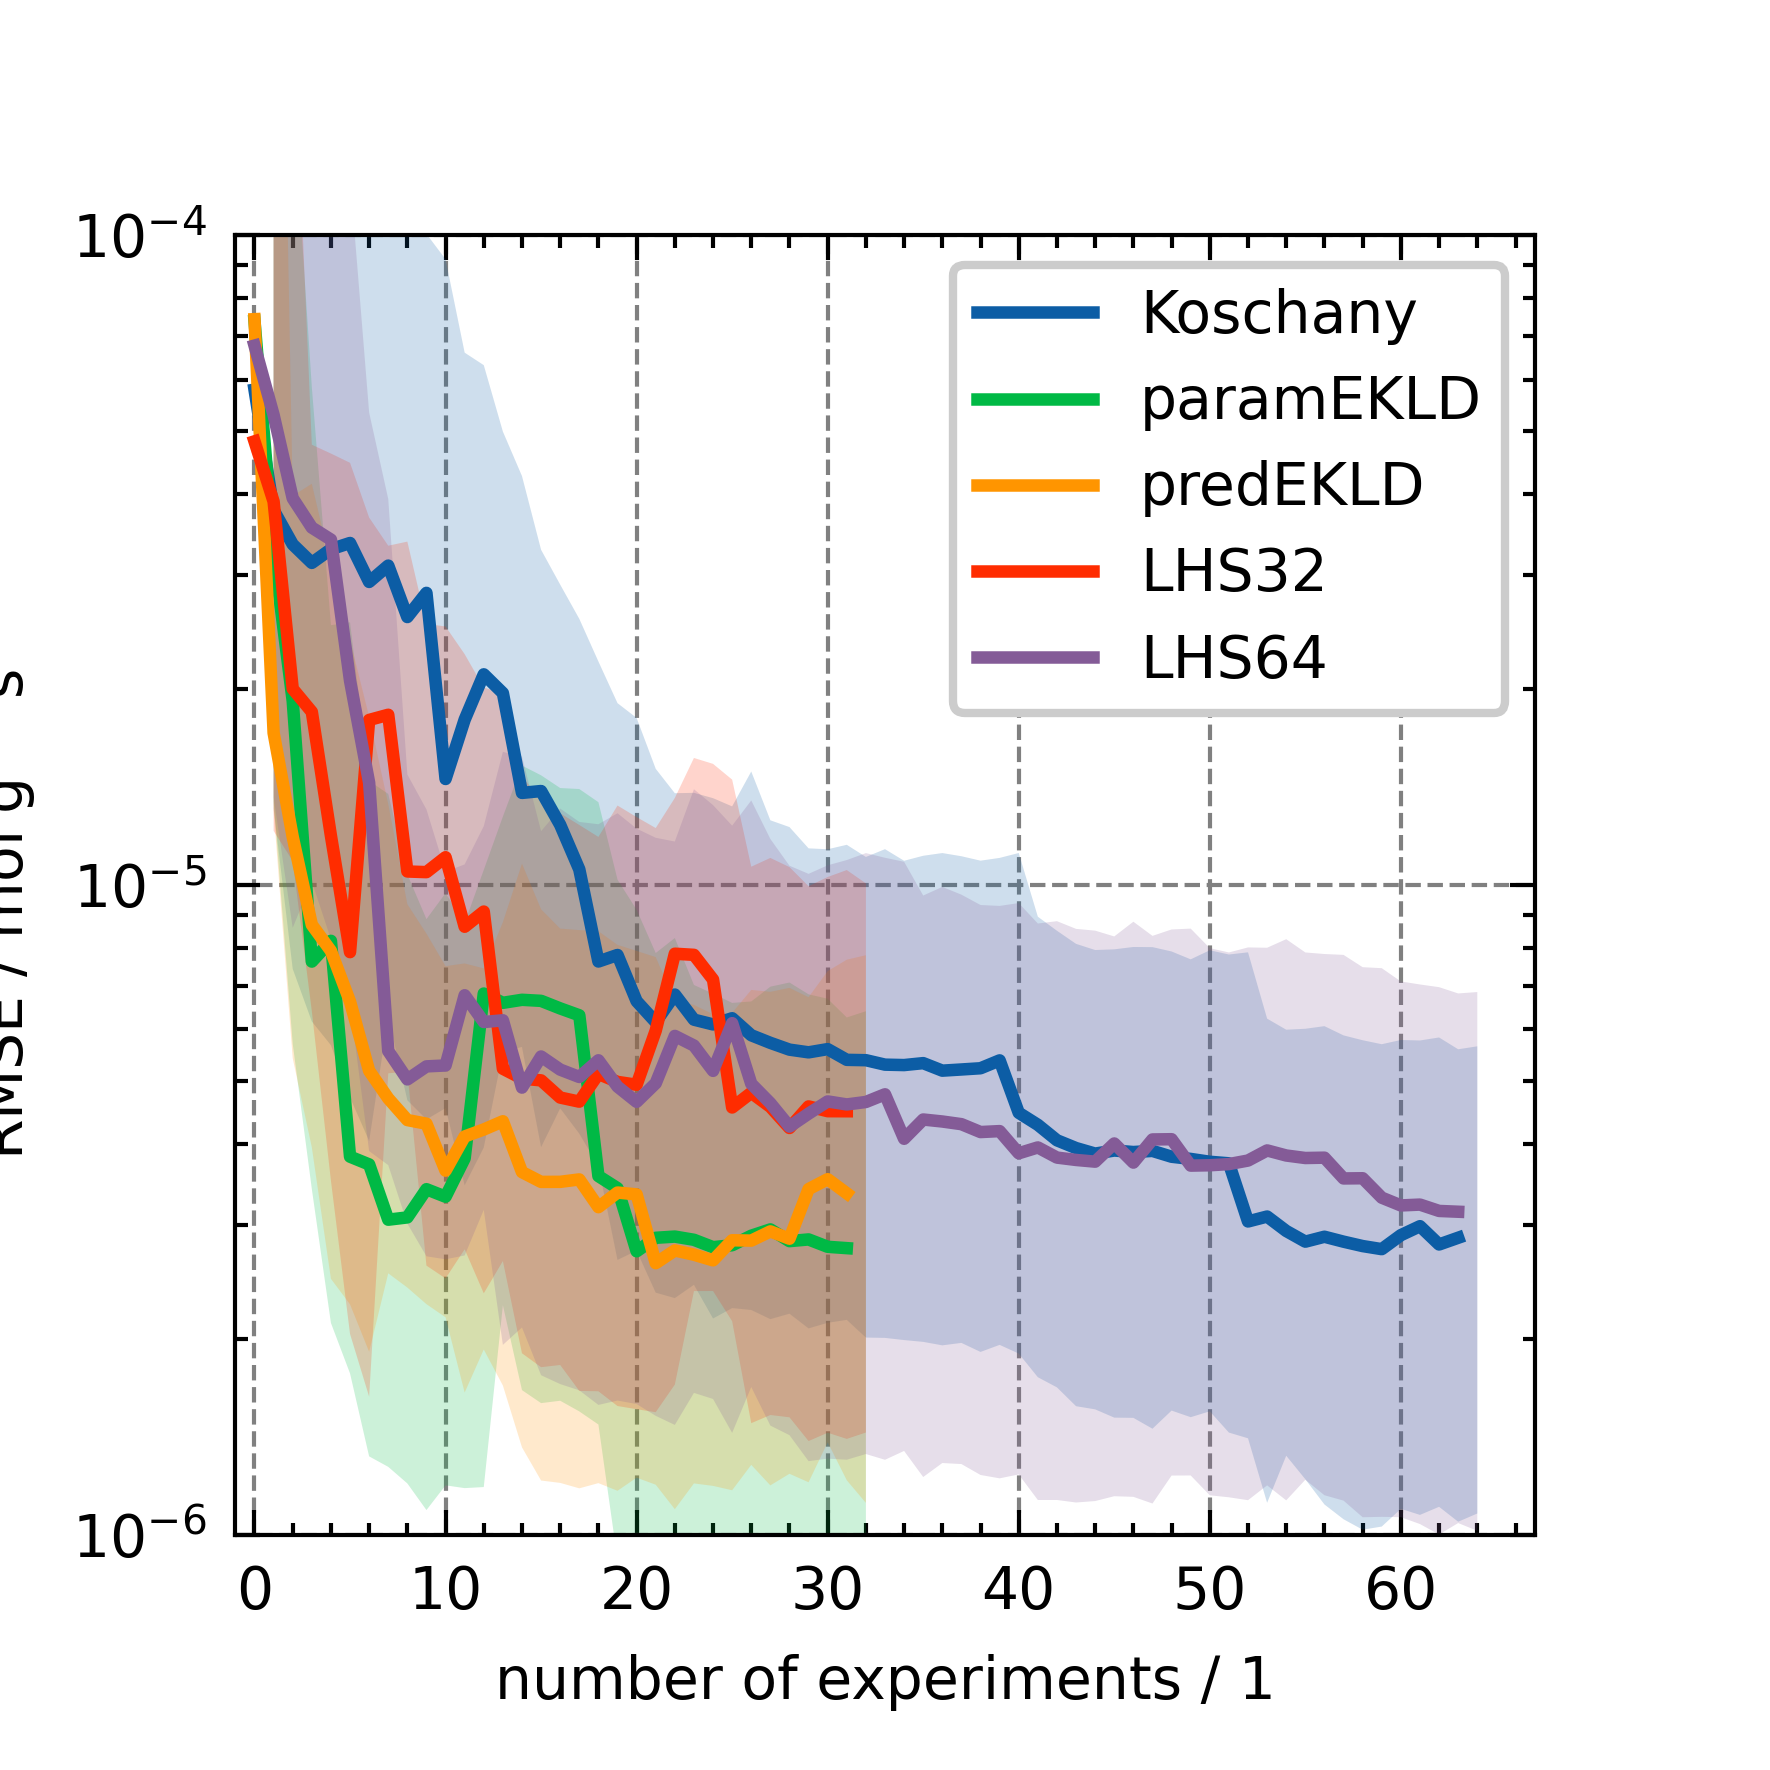

In [20]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(1e-6, 1e-4),
    xlim=(-1, 67),
)

for ov_dict in ov:
    print(ov_dict["DOE"])
    if ov_dict["DOE"] == "predEKLD DOE":
        label = "predEKLD"
    elif ov_dict["DOE"] == "paramEKLD DOE":
        label = "paramEKLD"
    elif ov_dict["DOE"] == "LHS32 DOE":
        label = "LHS32"
    elif ov_dict["DOE"] == "LHS64 DOE":
        label = "LHS64"
    else:
        label = "Koschany"
    ax.plot(
        np.median(ov_dict["RMSEs"], axis=1),
        label=label,
    )
    ax.fill_between(
        np.arange(1, len(ov_dict["RMSEs"]) + 1),
        np.quantile(ov_dict["RMSEs"], 0.025, axis=1),
        np.quantile(ov_dict["RMSEs"], 0.975, axis=1),
        alpha=0.2,
        ls="--",
        # edgecolor="gray",
    )
    ax.legend(frameon=True)

# plt.savefig("B_042_RMSE.png", dpi=600, bbox_inches="tight")

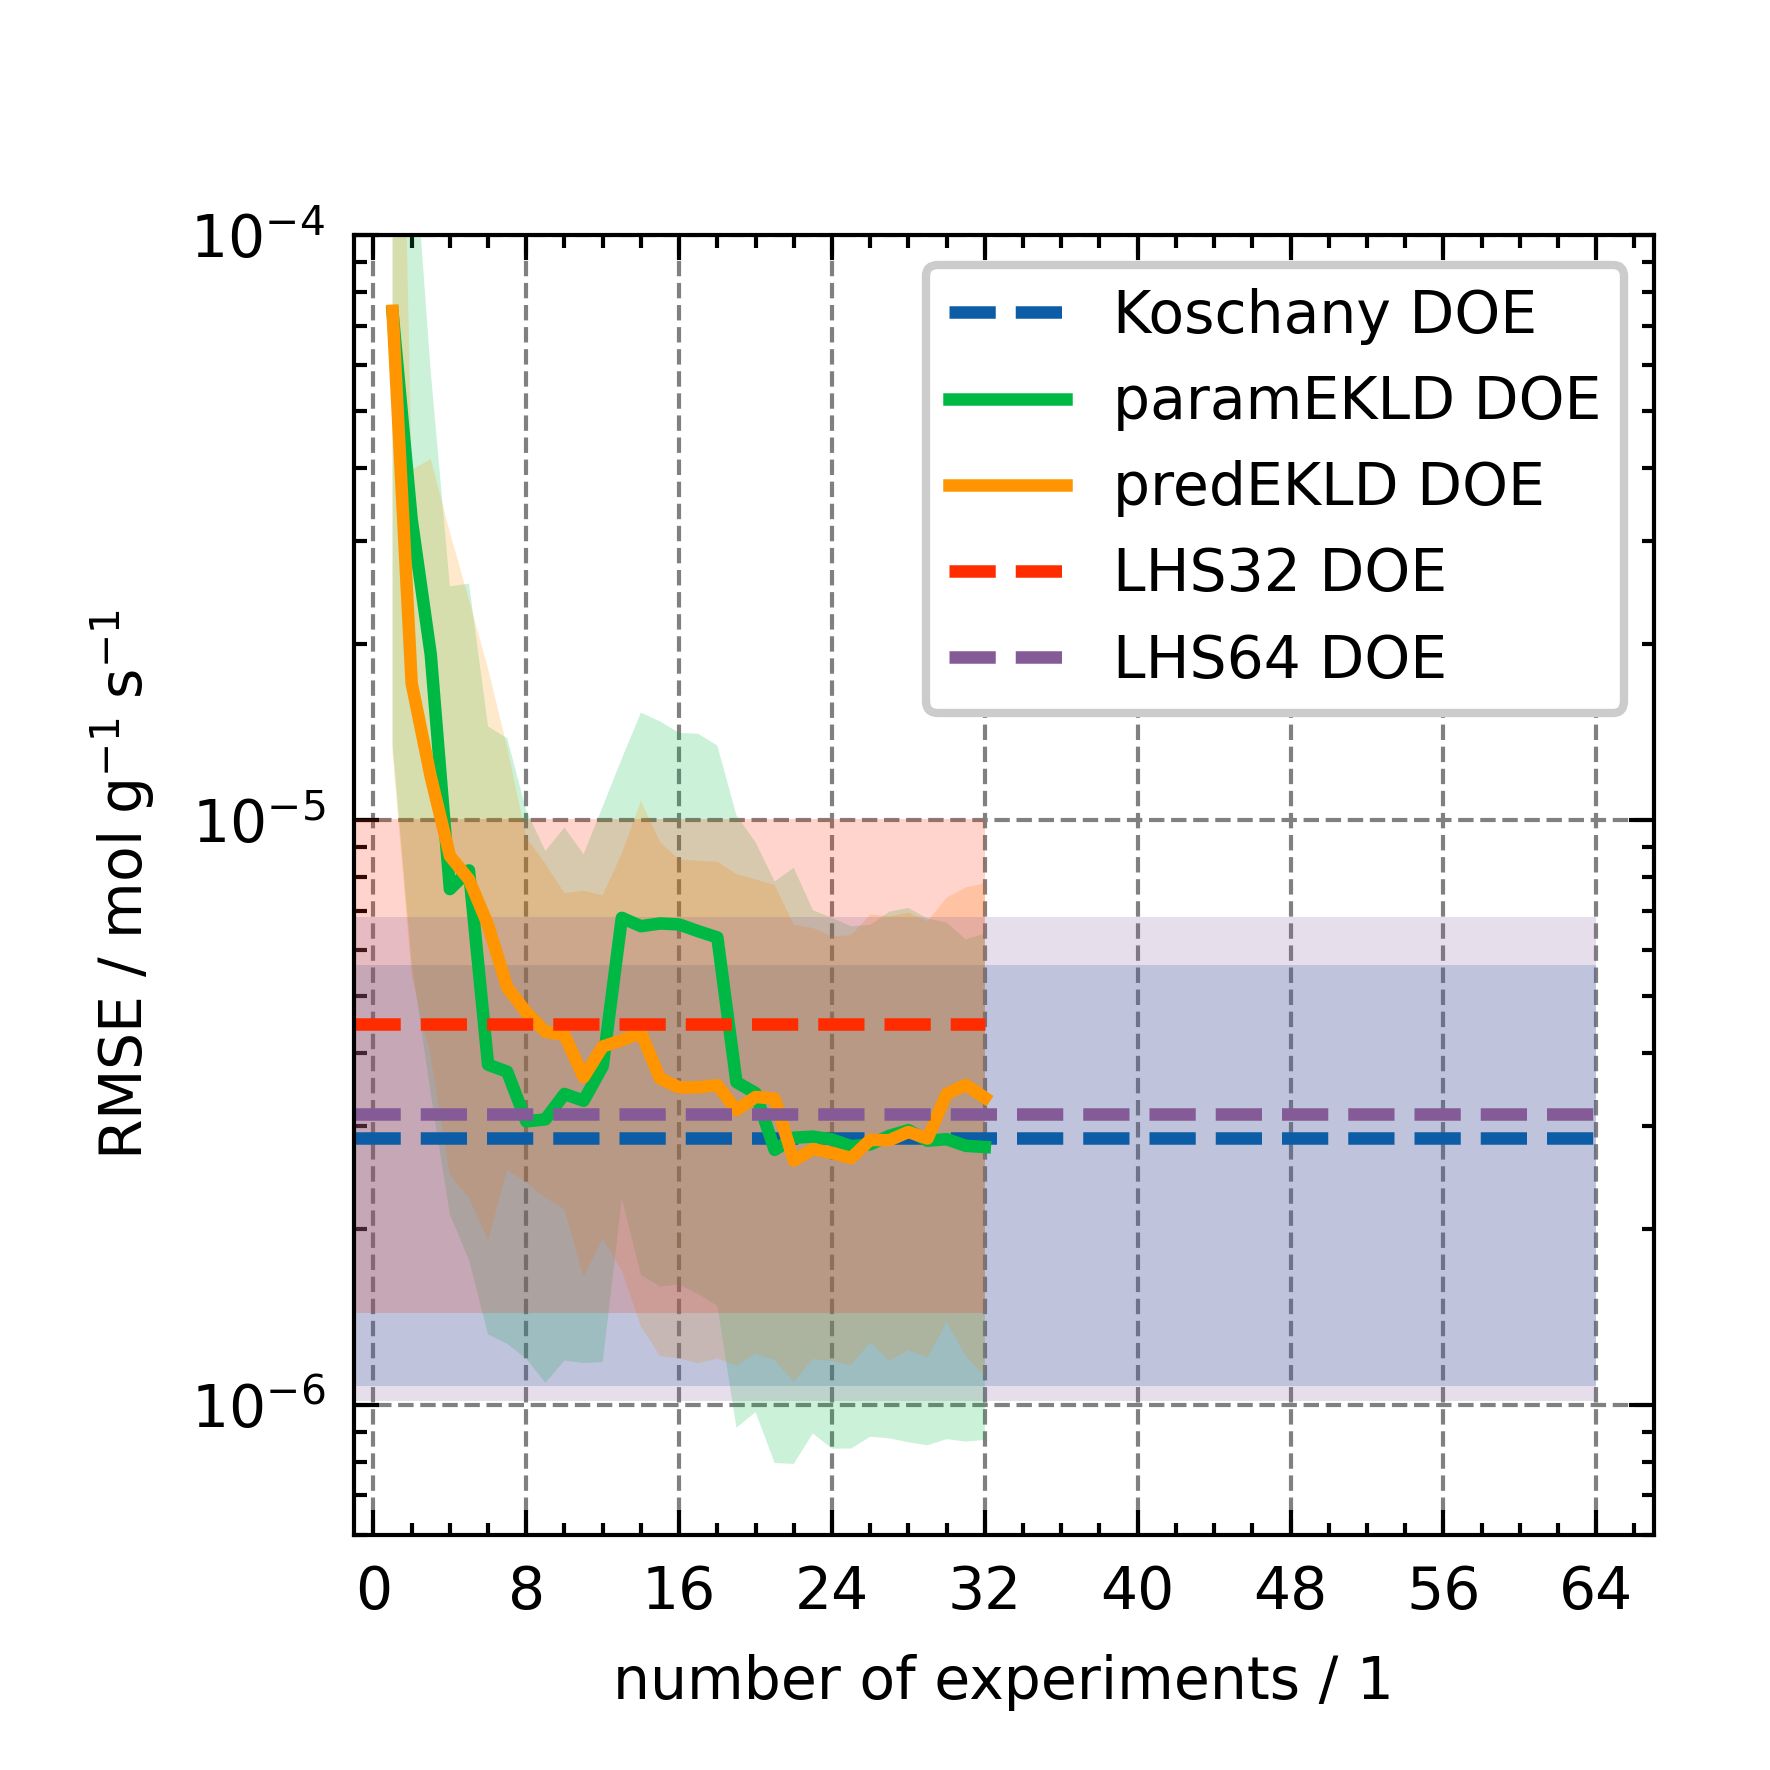

In [30]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, ov_dict in enumerate(ov):
    if ov_dict["DOE"] in ["Koschany DOE", "LHS32 DOE", "LHS64 DOE"]:
        ax.hlines(
            np.median(ov_dict["RMSEs"], axis=1)[-1],
            xmin=-1,
            xmax=len(ov_dict["RMSEs"]),
            label=ov_dict["DOE"],
            ls="--",
            color=colors[i],
        )
        ax.fill_between(
            np.arange(-1, len(ov_dict["RMSEs"]) + 1),
            np.quantile(ov_dict["RMSEs"], 0.025, axis=1)[-1],
            np.quantile(ov_dict["RMSEs"], 0.975, axis=1)[-1],
            alpha=0.2,
            # ls="--",
            facecolor=colors[i],
            # edgecolor=colors[i],
            # edgecolor="gray",
        )
    else:
        ax.plot(
            np.arange(1, len(ov_dict["RMSEs"]) + 1),
            np.median(ov_dict["RMSEs"], axis=1),
            # "o--",
            # ms=4,
            # lw=1,
            label=ov_dict["DOE"],
            color=colors[i],
        )
        ax.fill_between(
            np.arange(1, len(ov_dict["RMSEs"]) + 1),
            np.quantile(ov_dict["RMSEs"], 0.025, axis=1),
            np.quantile(ov_dict["RMSEs"], 0.975, axis=1),
            alpha=0.2,
            # edgecolor=colors[i],
            # ls="--",
            facecolor=colors[i],
            # edgecolor="gray",
        )
    ax.legend(frameon=True)

plt.savefig("figures/KinFit_RMSE_wLHS.png")
plt.savefig("figures/KinFit_RMSE_wLHS.pdf")
plt.savefig("figures/KinFit_RMSE_wLHS.svg")

TypeError: hdi got an unexpected keyword argument: 'hdi_prob'

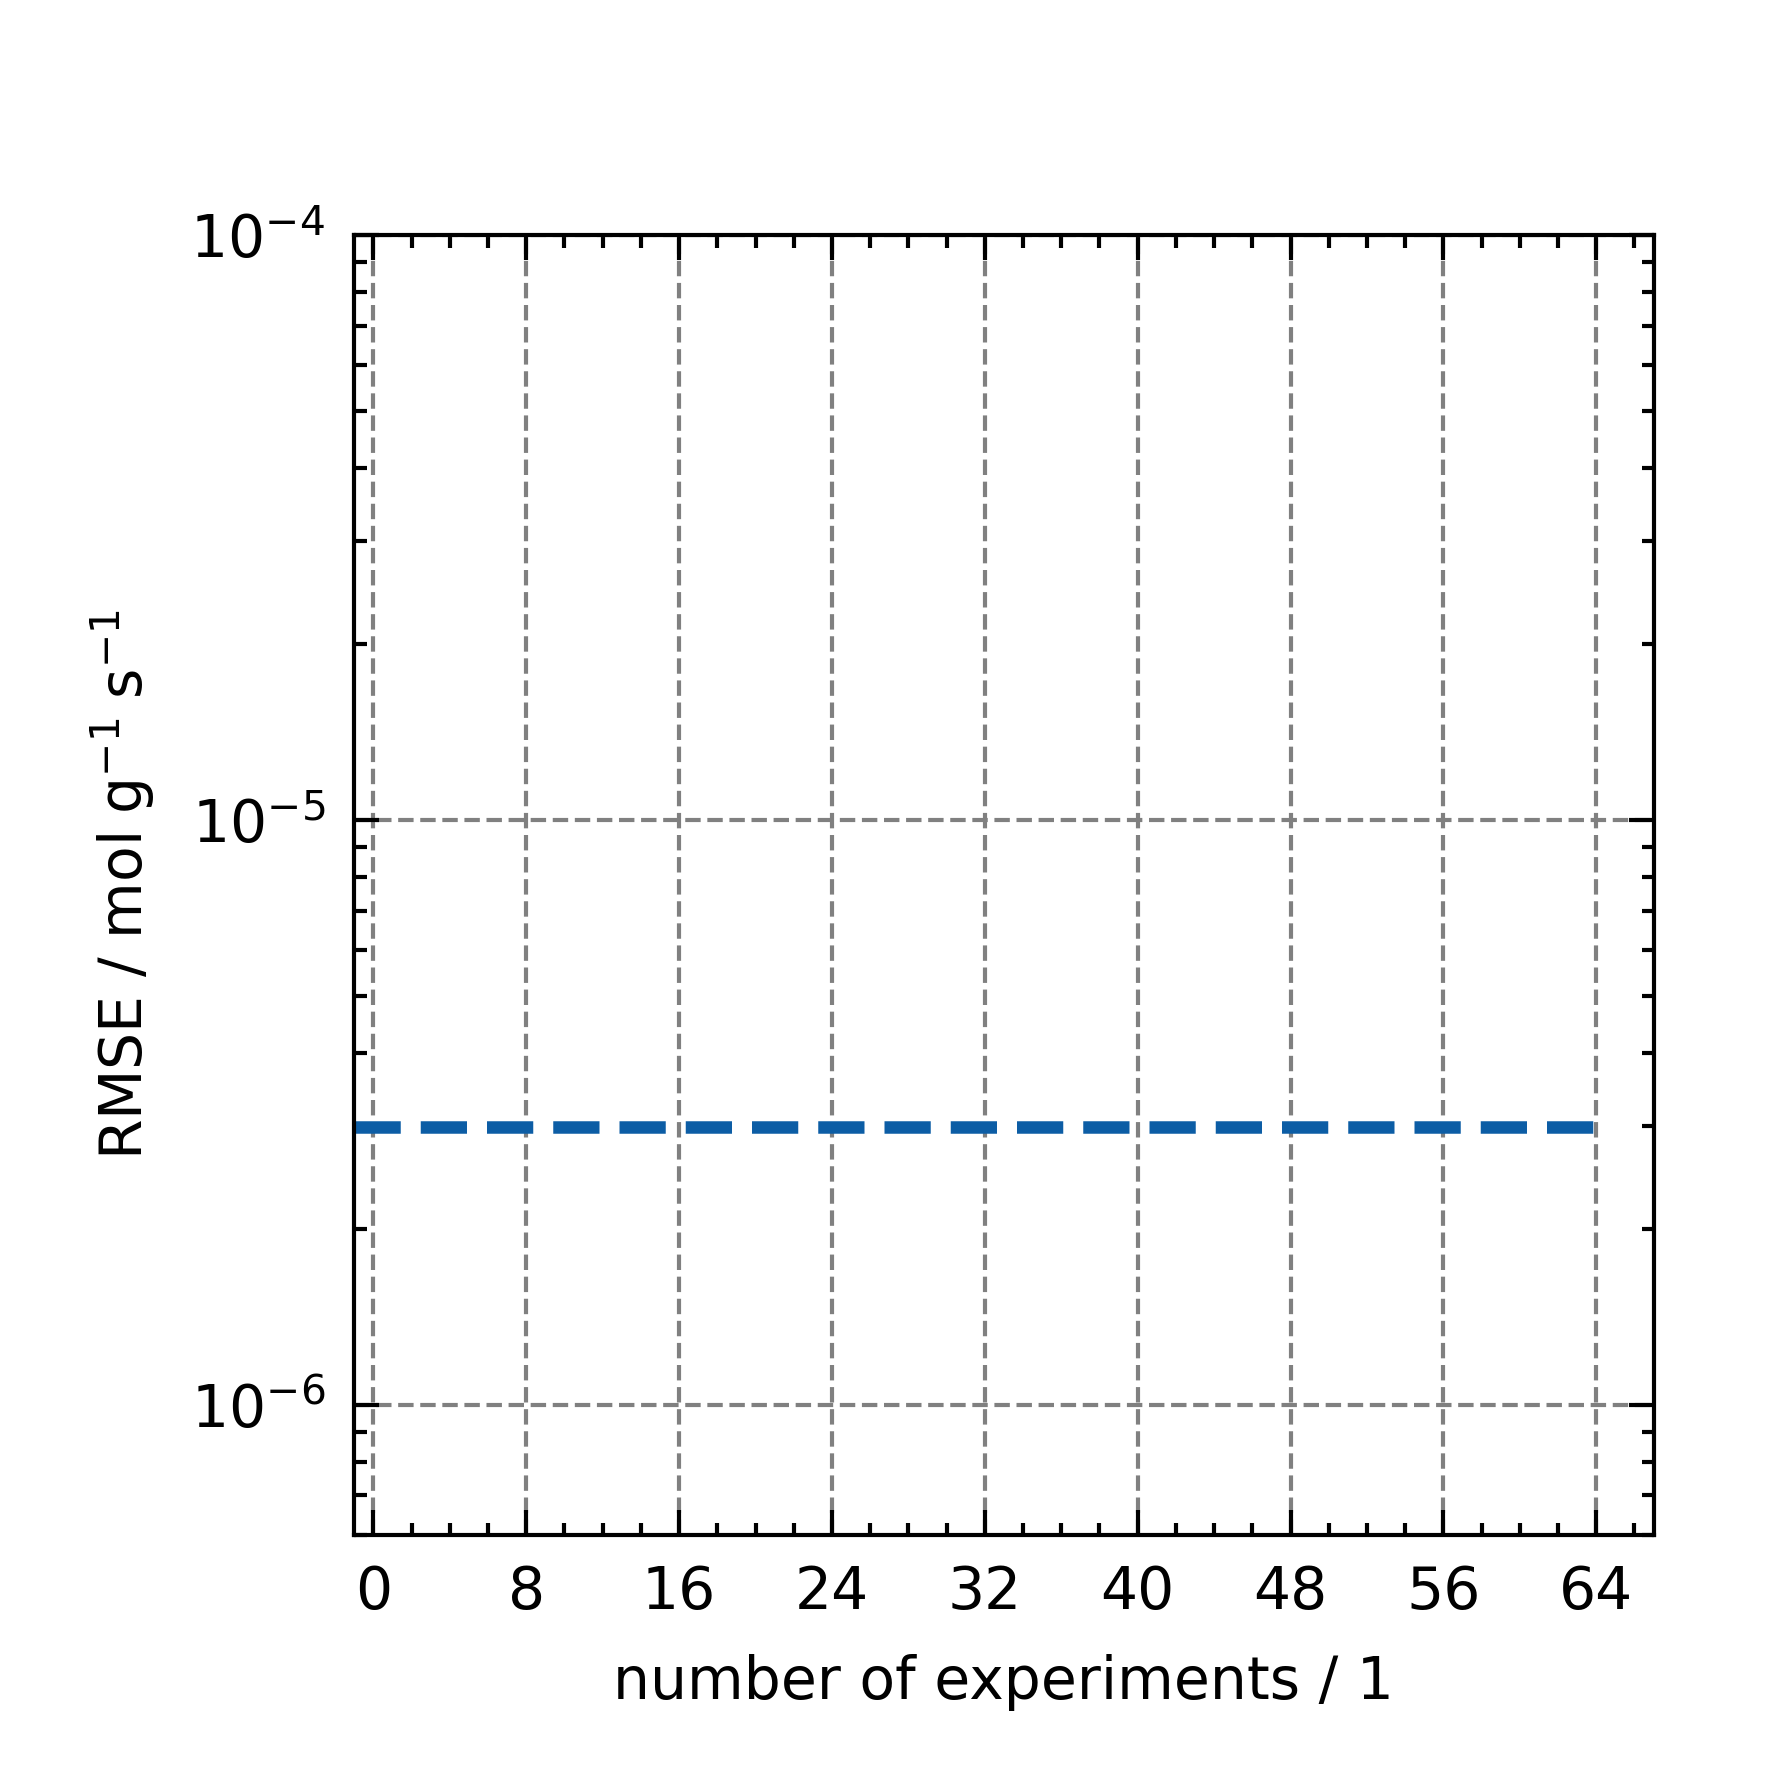

In [ ]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, ov_dict in enumerate(ov):
    if ov_dict["DOE"] in ["Koschany DOE", "LHS32 DOE", "LHS64 DOE"]:
        ax.hlines(
            np.mean(ov_dict["RMSEs"], axis=1)[-1],
            xmin=-1,
            xmax=64,
            label=ov_dict["DOE"],
            ls="--",
            color=colors[i],
        )
        HDI = az.hdi(ov_dict["RMSEs"][-1], prob=0.95)
        ax.fill_between(
            np.arange(-1, len(ov_dict["RMSEs"]) + 1),
            HDI[0],
            HDI[1],
            alpha=0.2,
            # ls="--",
            facecolor=colors[i],
            # edgecolor="gray",
        )
    else:
        ax.plot(
            np.arange(1, len(ov_dict["RMSEs"]) + 1),
            np.mean(ov_dict["RMSEs"], axis=1),
            # "o--",
            # ms=4,
            # lw=1,
            label=ov_dict["DOE"],
            color=colors[i],
        )
        HDI = az.hdi(ov_dict["RMSEs"].T, prob=0.95)
        print(HDI.shape)
        ax.fill_between(
            np.arange(1, len(ov_dict["RMSEs"]) + 1),
            HDI[:, 0],
            HDI[:, 1],
            alpha=0.2,
            # ls="--",
            facecolor=colors[i],
            # edgecolor="gray",
        )
    ax.legend(frameon=True)

# plt.savefig("figures/KinFit_RMSE.png")
# plt.savefig("figures/KinFit_RMSE.pdf")
# plt.savefig("figures/KinFit_RMSE.svg")

### Information Gain

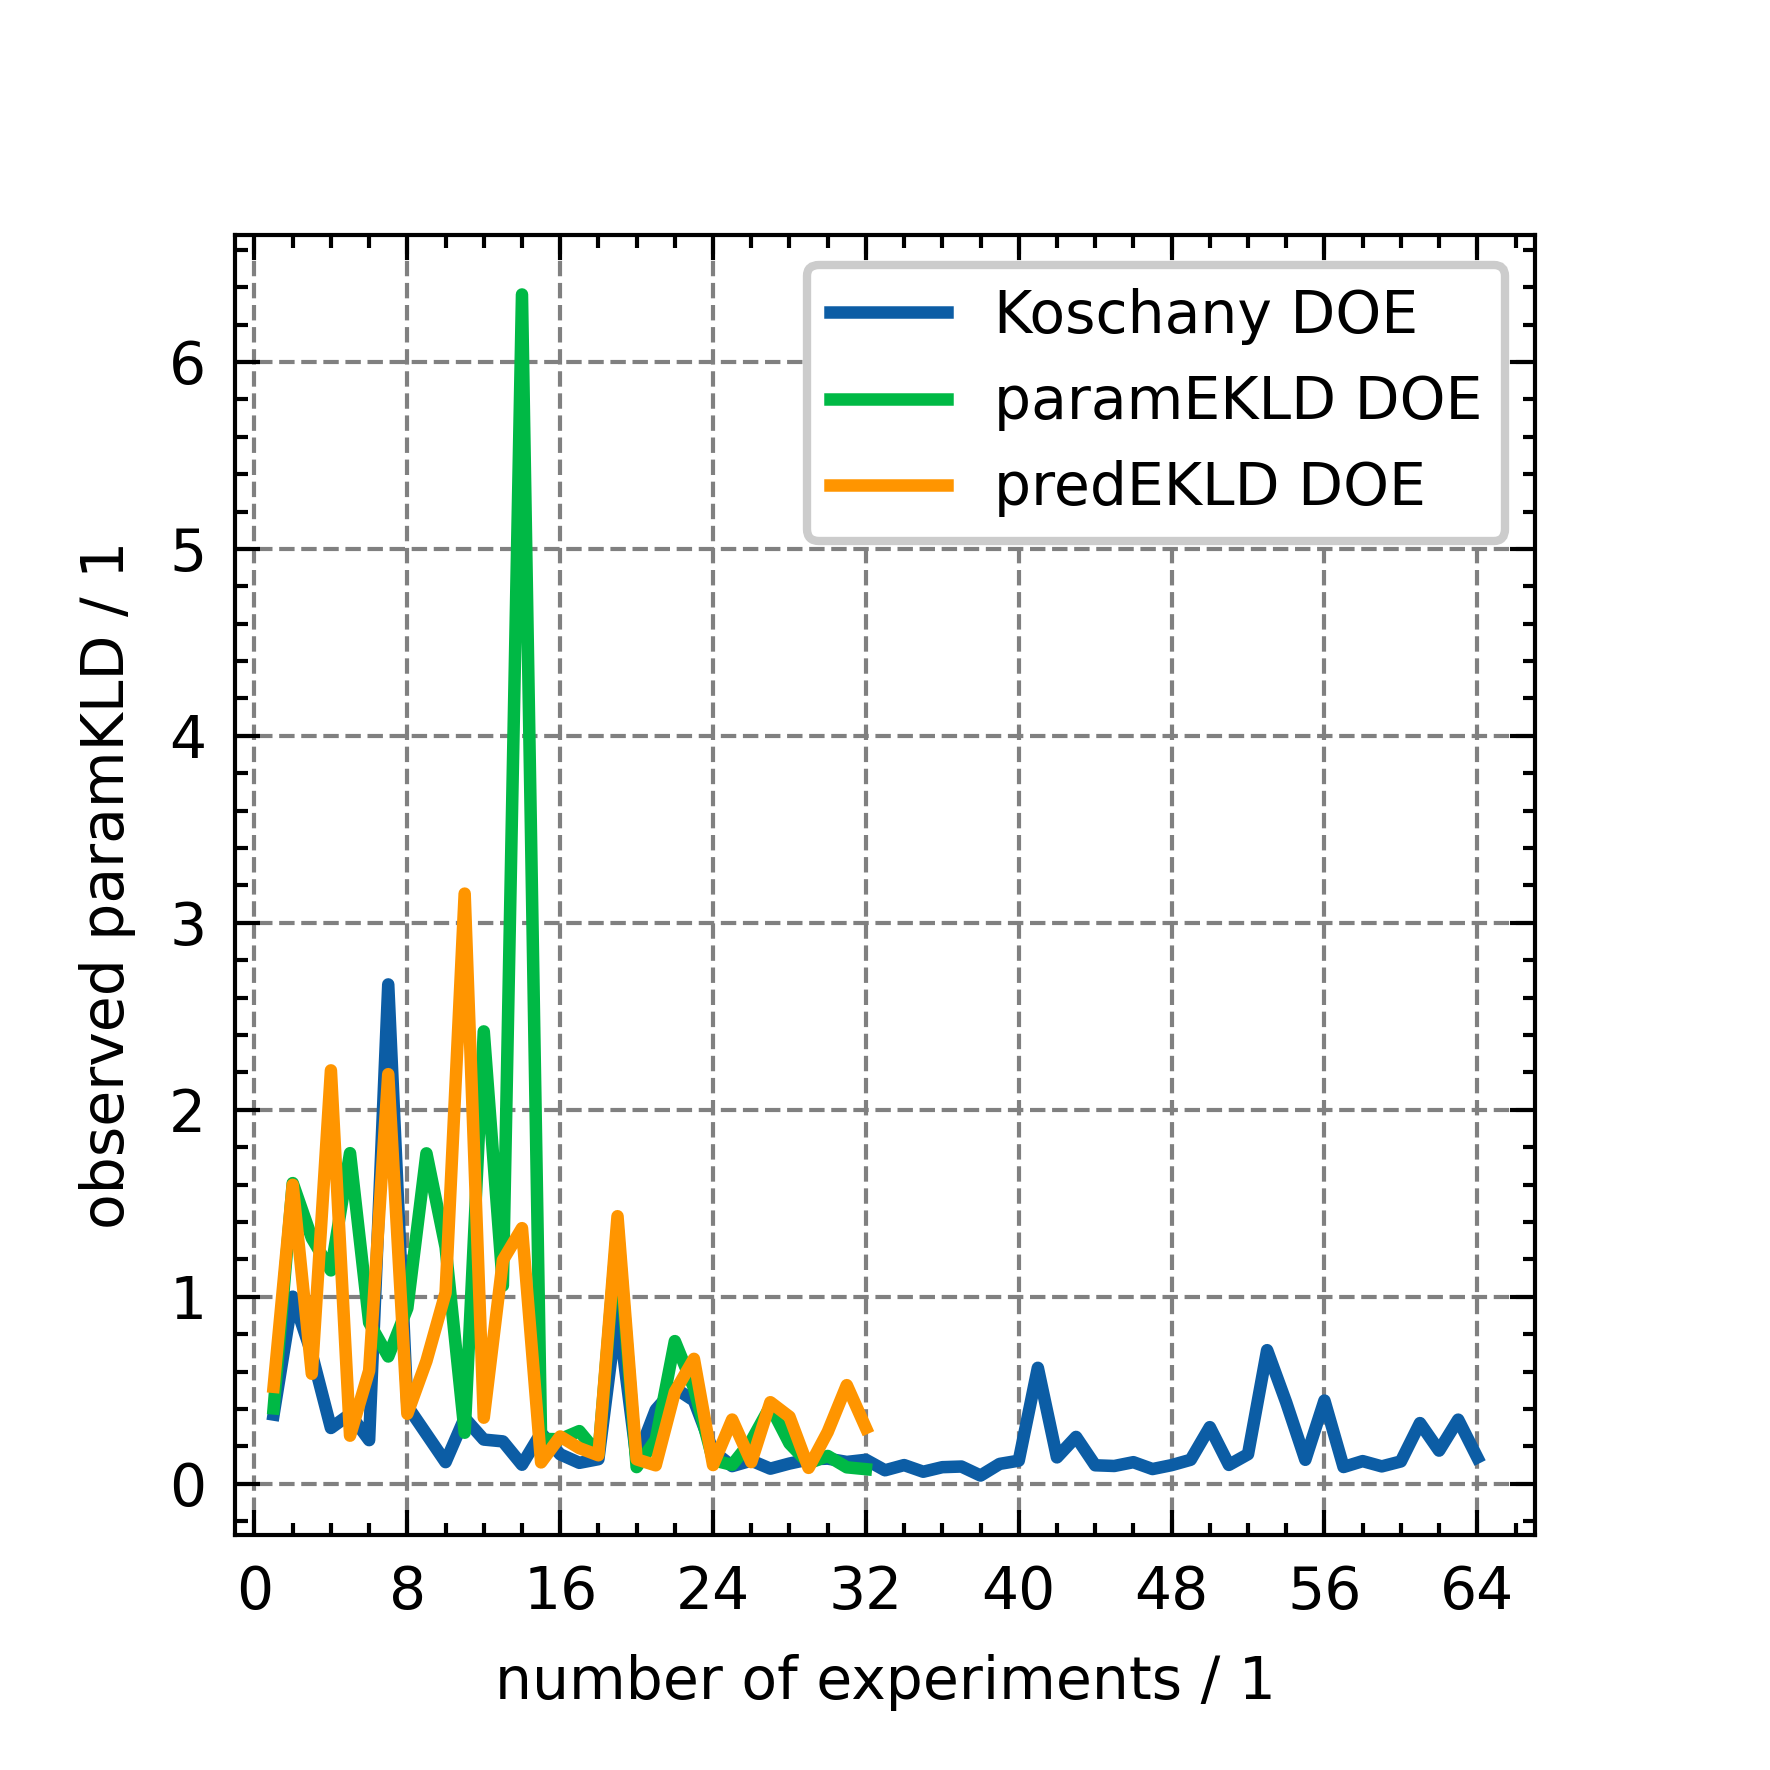

In [ ]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel="observed paramKLD / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
)
for i, ov_dict in enumerate(ov):
    ax.plot(
        np.arange(len(ov_dict["paramEKLDS"])) + 1,
        ov_dict["paramEKLDS"],
        label=ov_dict["DOE"],
    )
    ax.legend()

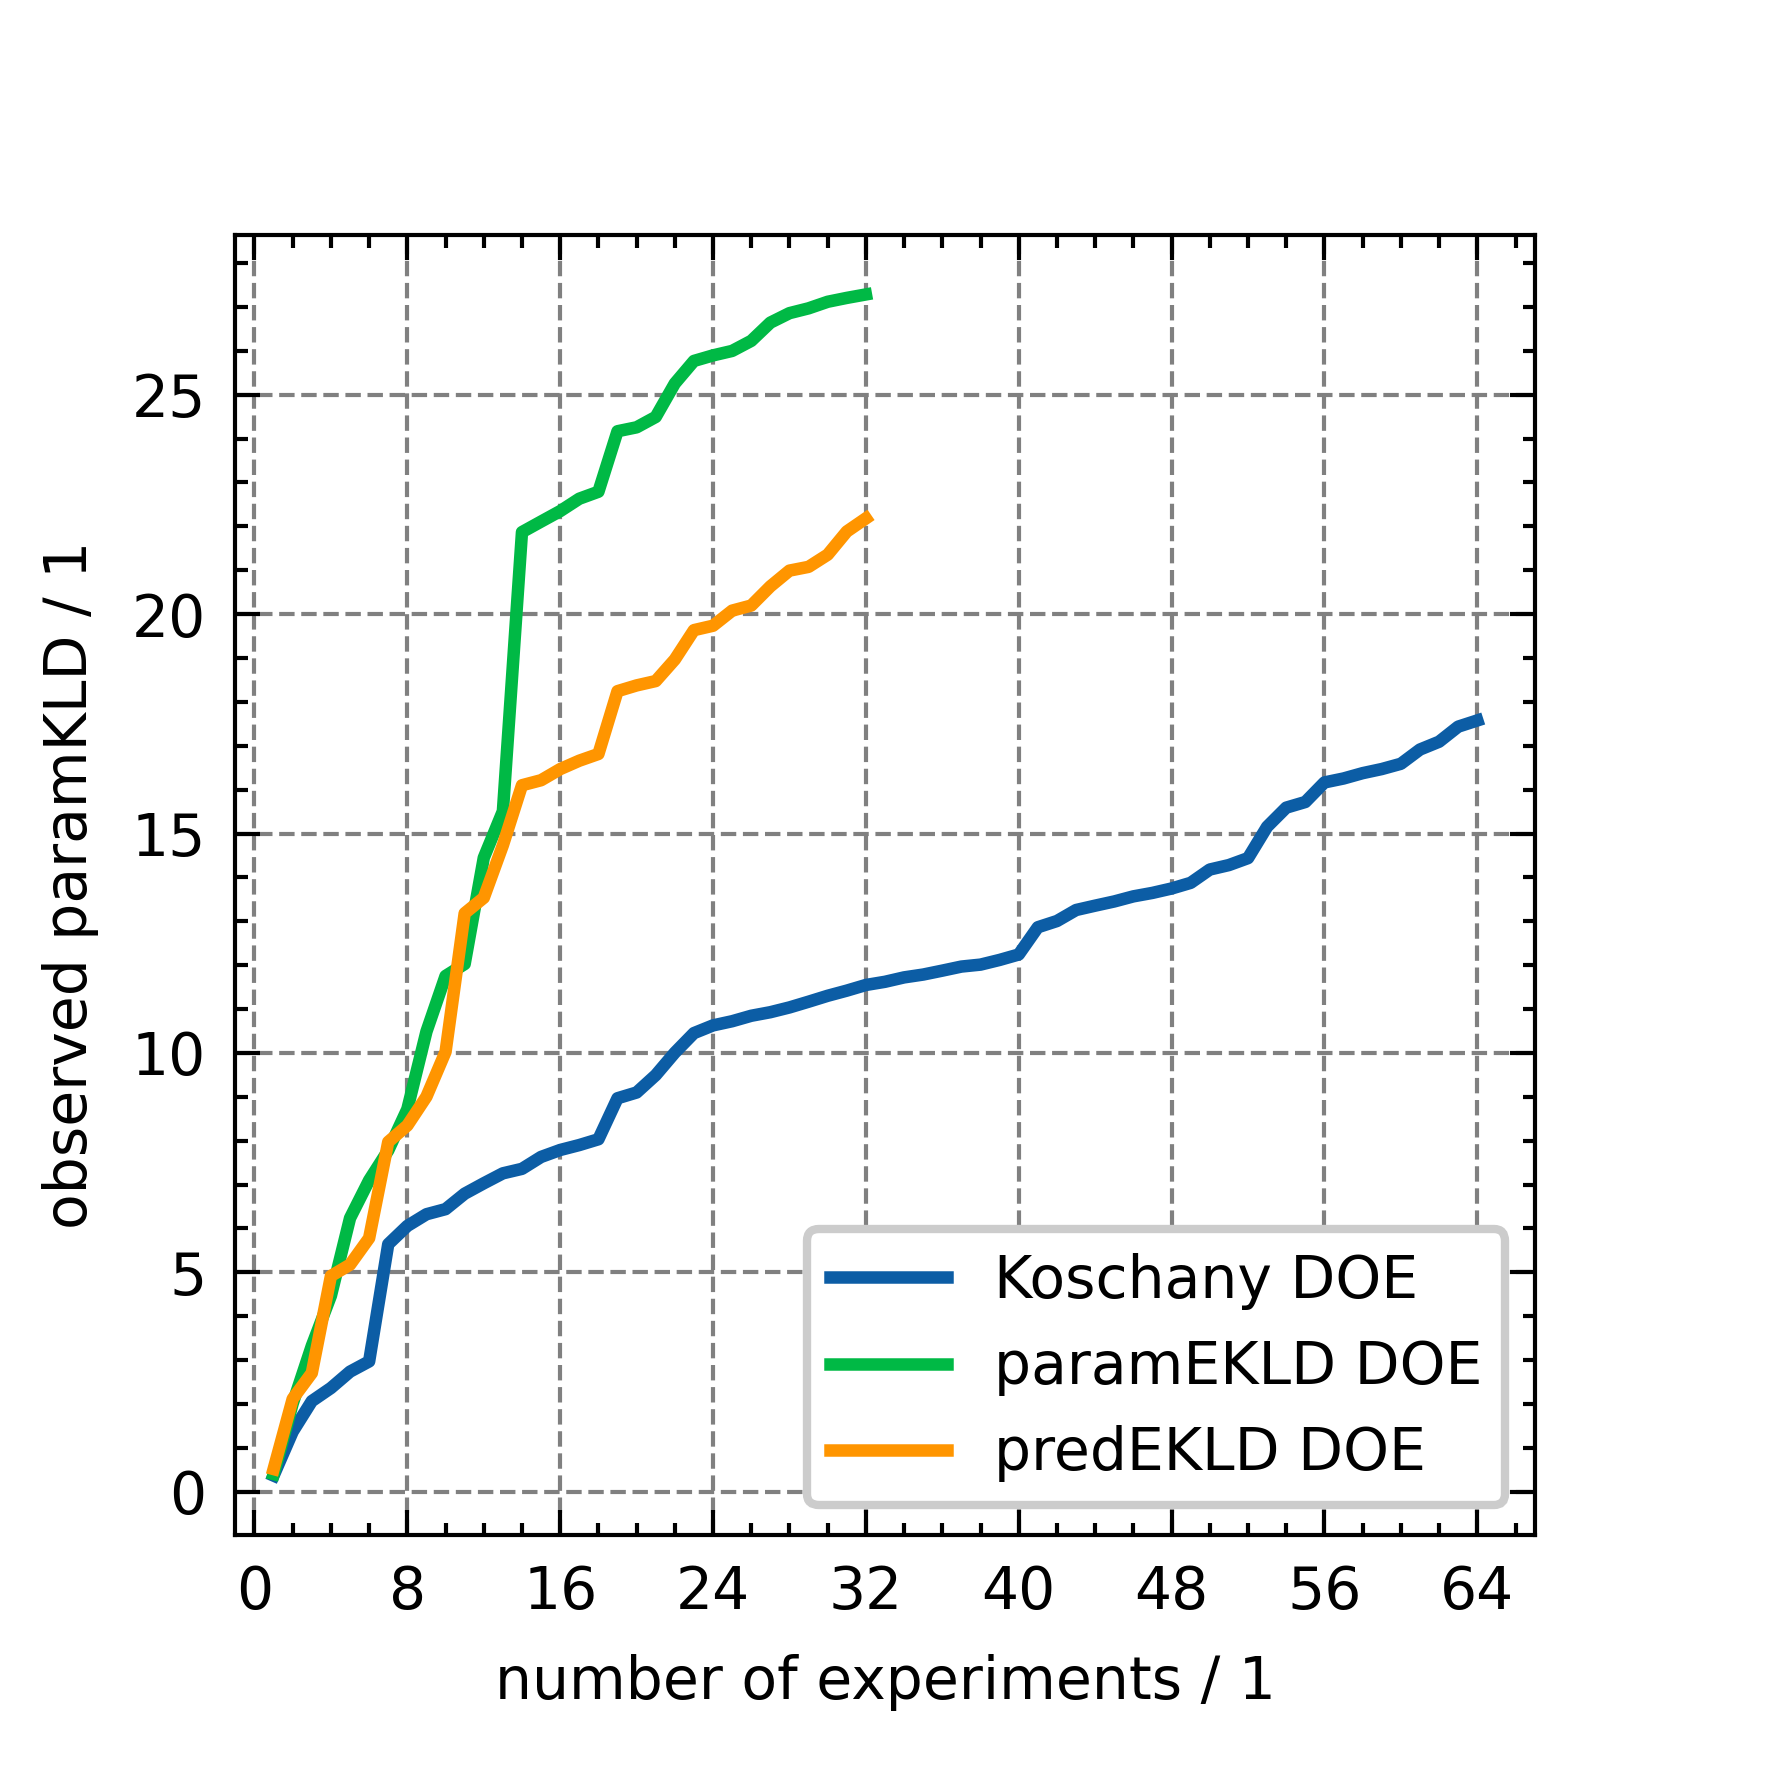

In [ ]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel="observed paramKLD / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
)
for i, ov_dict in enumerate(ov):
    ax.plot(
        np.arange(len(ov_dict["paramEKLDS"])) + 1,
        np.cumsum(ov_dict["paramEKLDS"]),
        label=ov_dict["DOE"],
    )
    ax.legend()

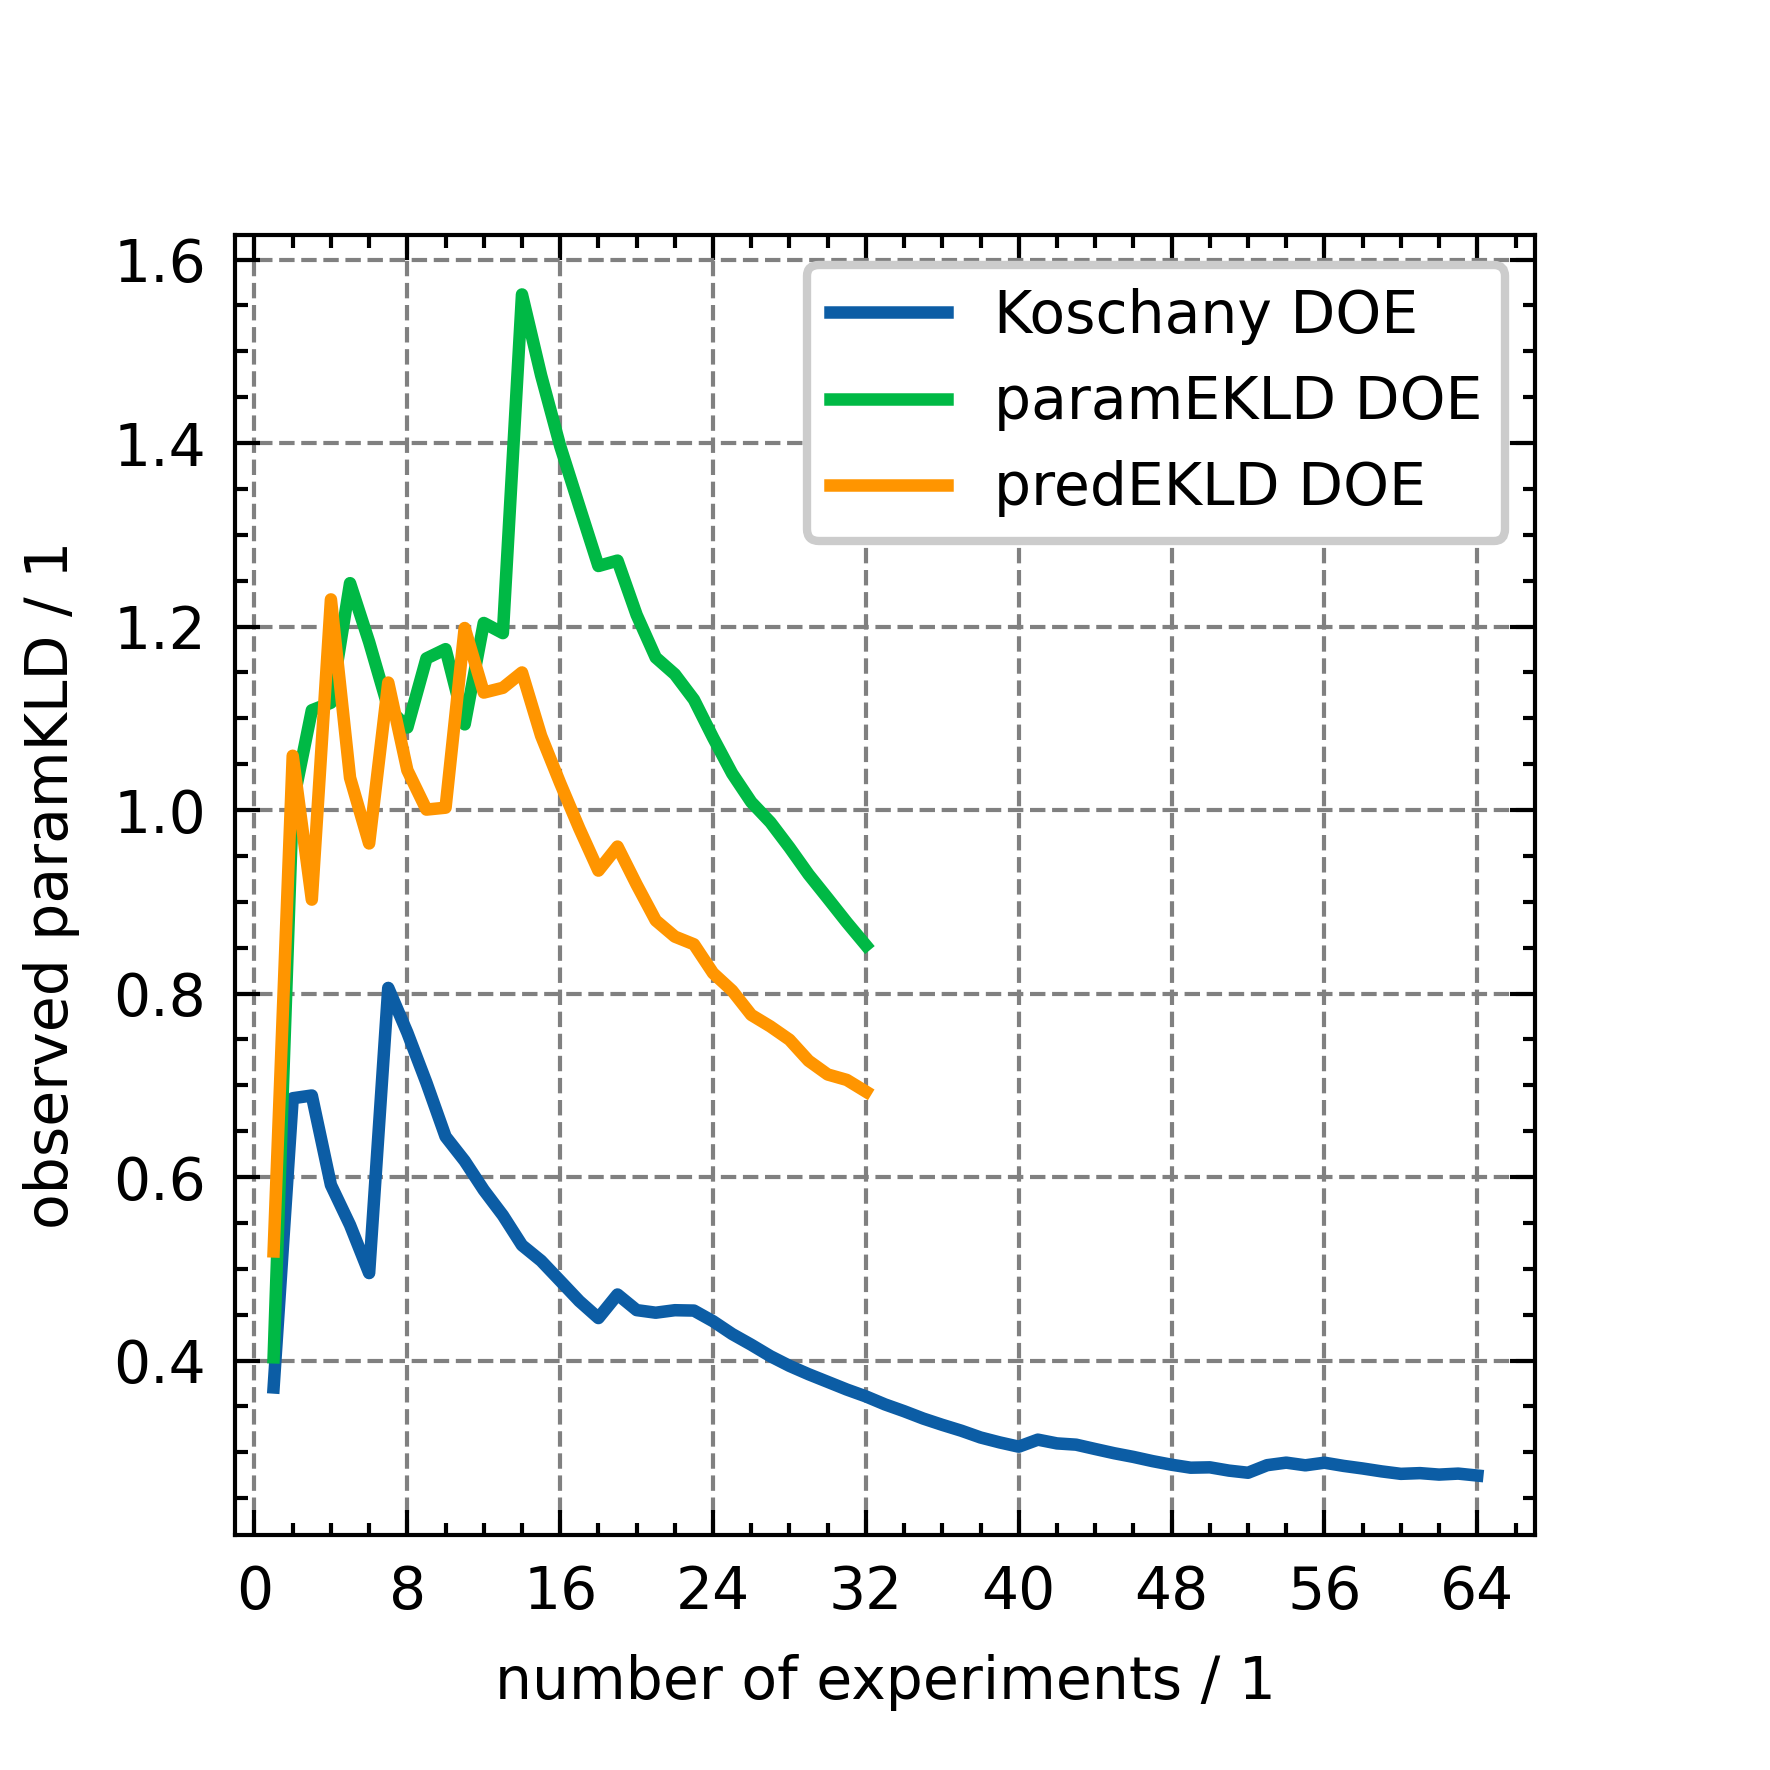

In [ ]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel="observed paramKLD / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
)
for i, ov_dict in enumerate(ov):
    ax.plot(
        x := np.arange(len(ov_dict["paramEKLDS"])) + 1,
        np.cumsum(ov_dict["paramEKLDS"]) / x,
        label=ov_dict["DOE"],
    )
    ax.legend()

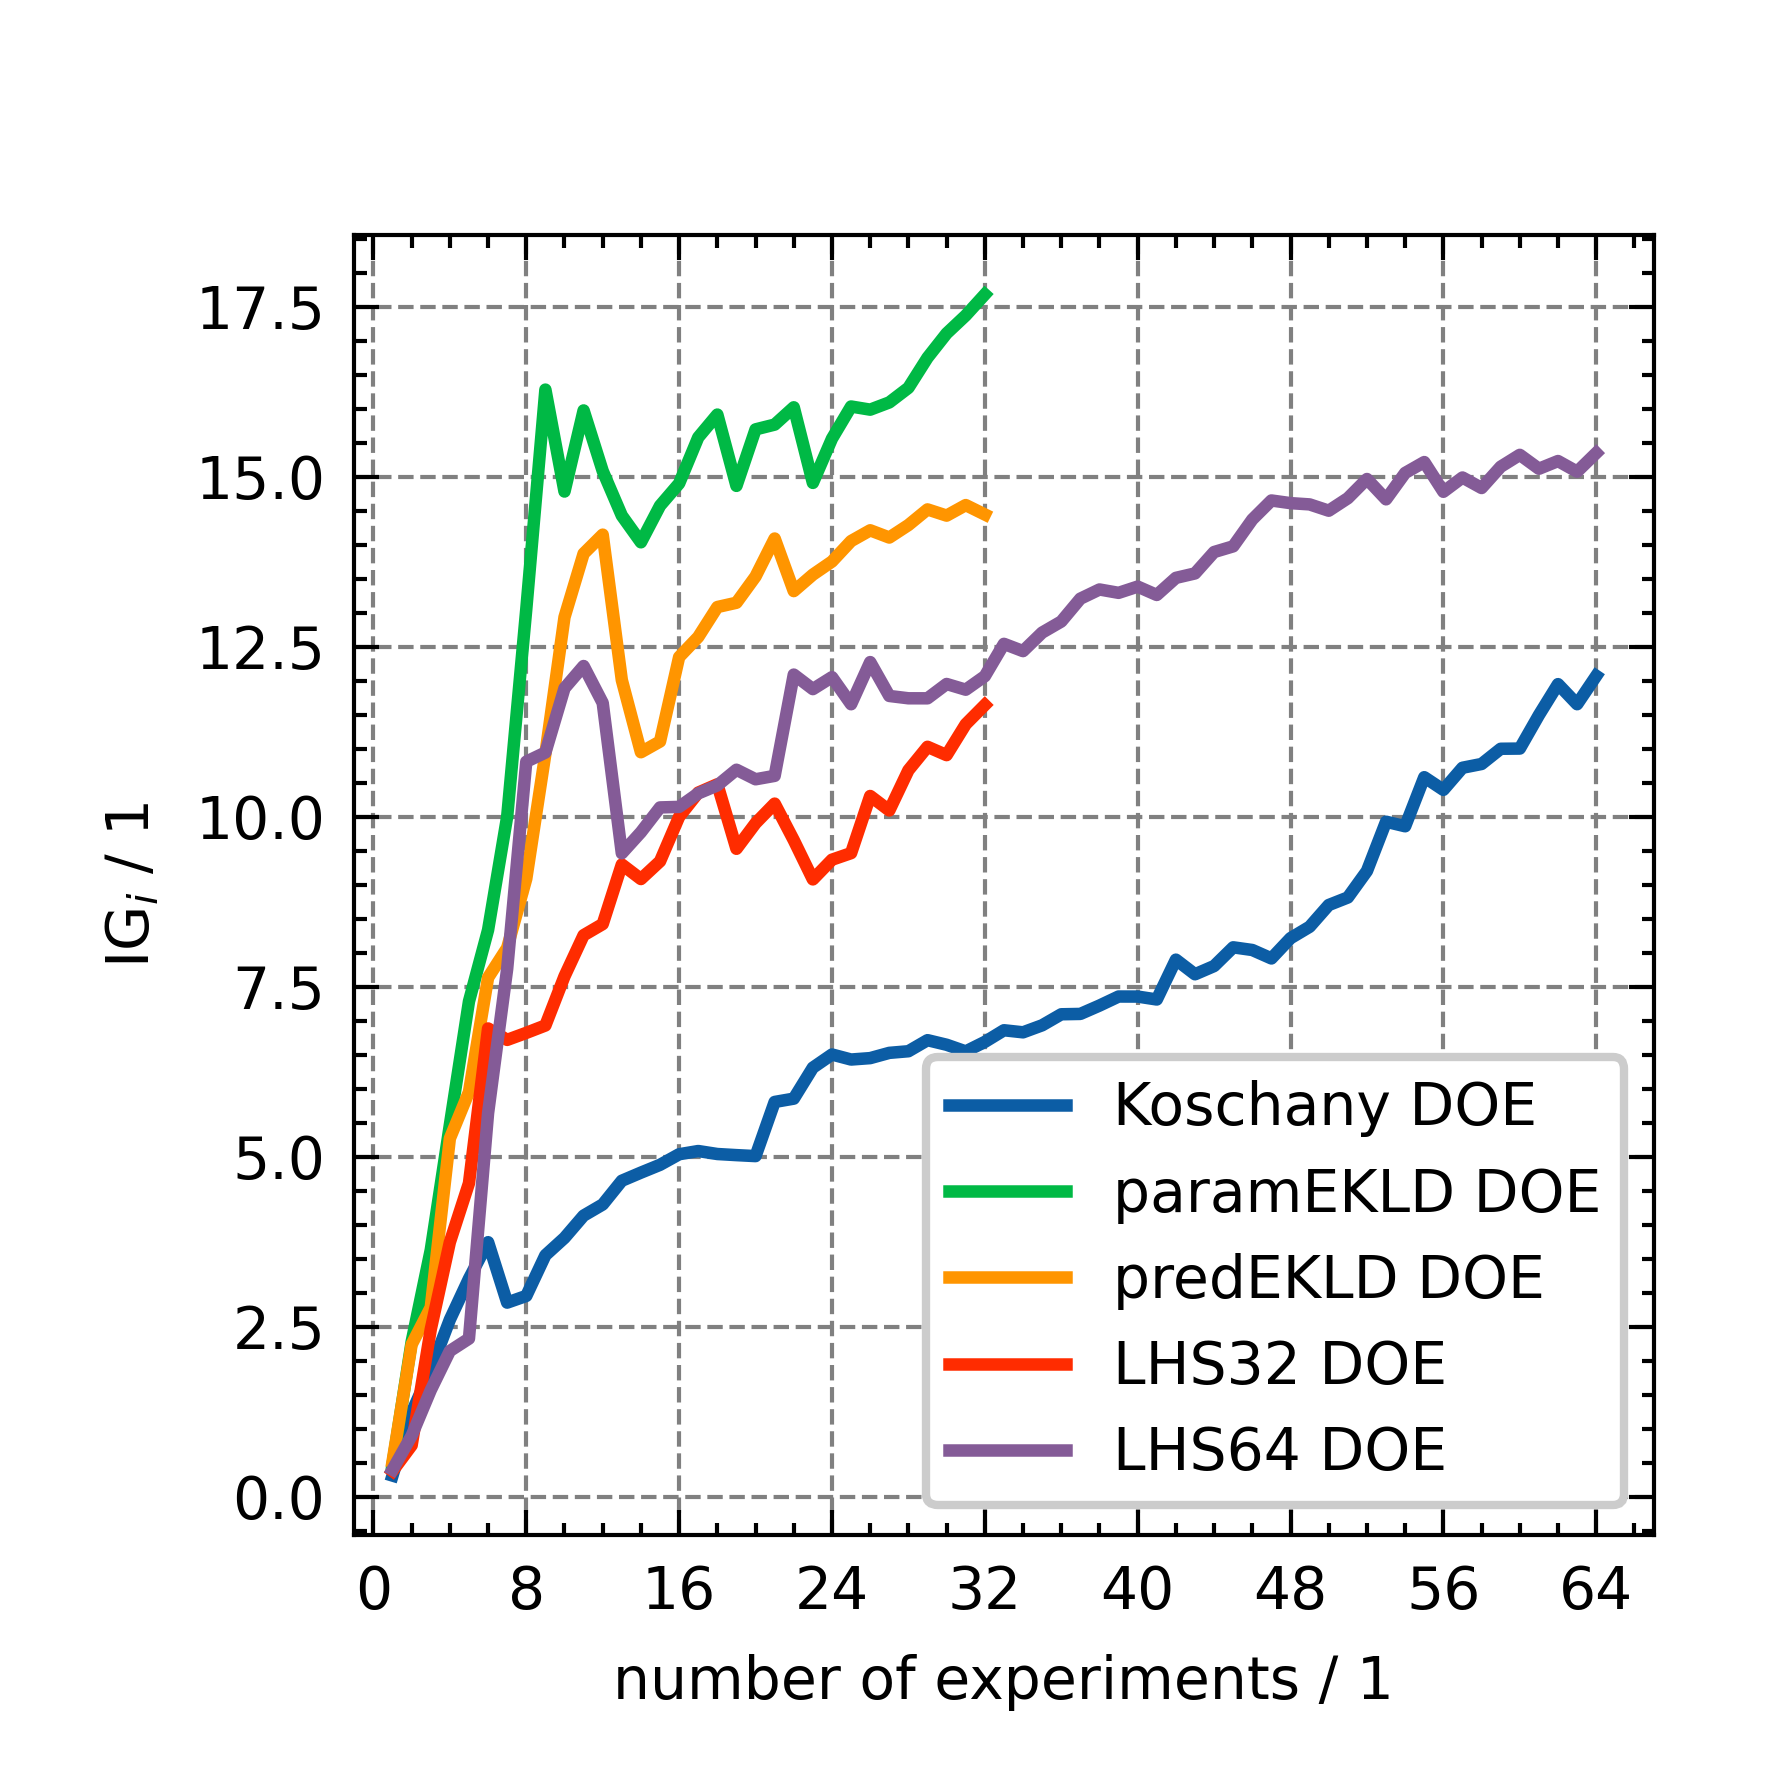

In [29]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"$\mathrm{IG}_i$ / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)
for i, ov_dict in enumerate(ov):
    ax.plot(
        np.arange(len(ov_dict["paramEKLDS_to_prior"])) + 1,
        ov_dict["paramEKLDS_to_prior"],
        label=ov_dict["DOE"],
    )
    ax.legend()

# plt.savefig("figures/KinFit_IG.png")
# plt.savefig("figures/KinFit_IG.pdf")
# plt.savefig("figures/KinFit_IG.svg")

### Posterior Predictive

In [ ]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])
    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range for evaluation
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(
        T, p, c2h, c2m, c2w, c2i, rel_noise_std=0.0
    )

    return true_rates


def plot_predictions(fig, ax, posterior_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")
    return fig, ax

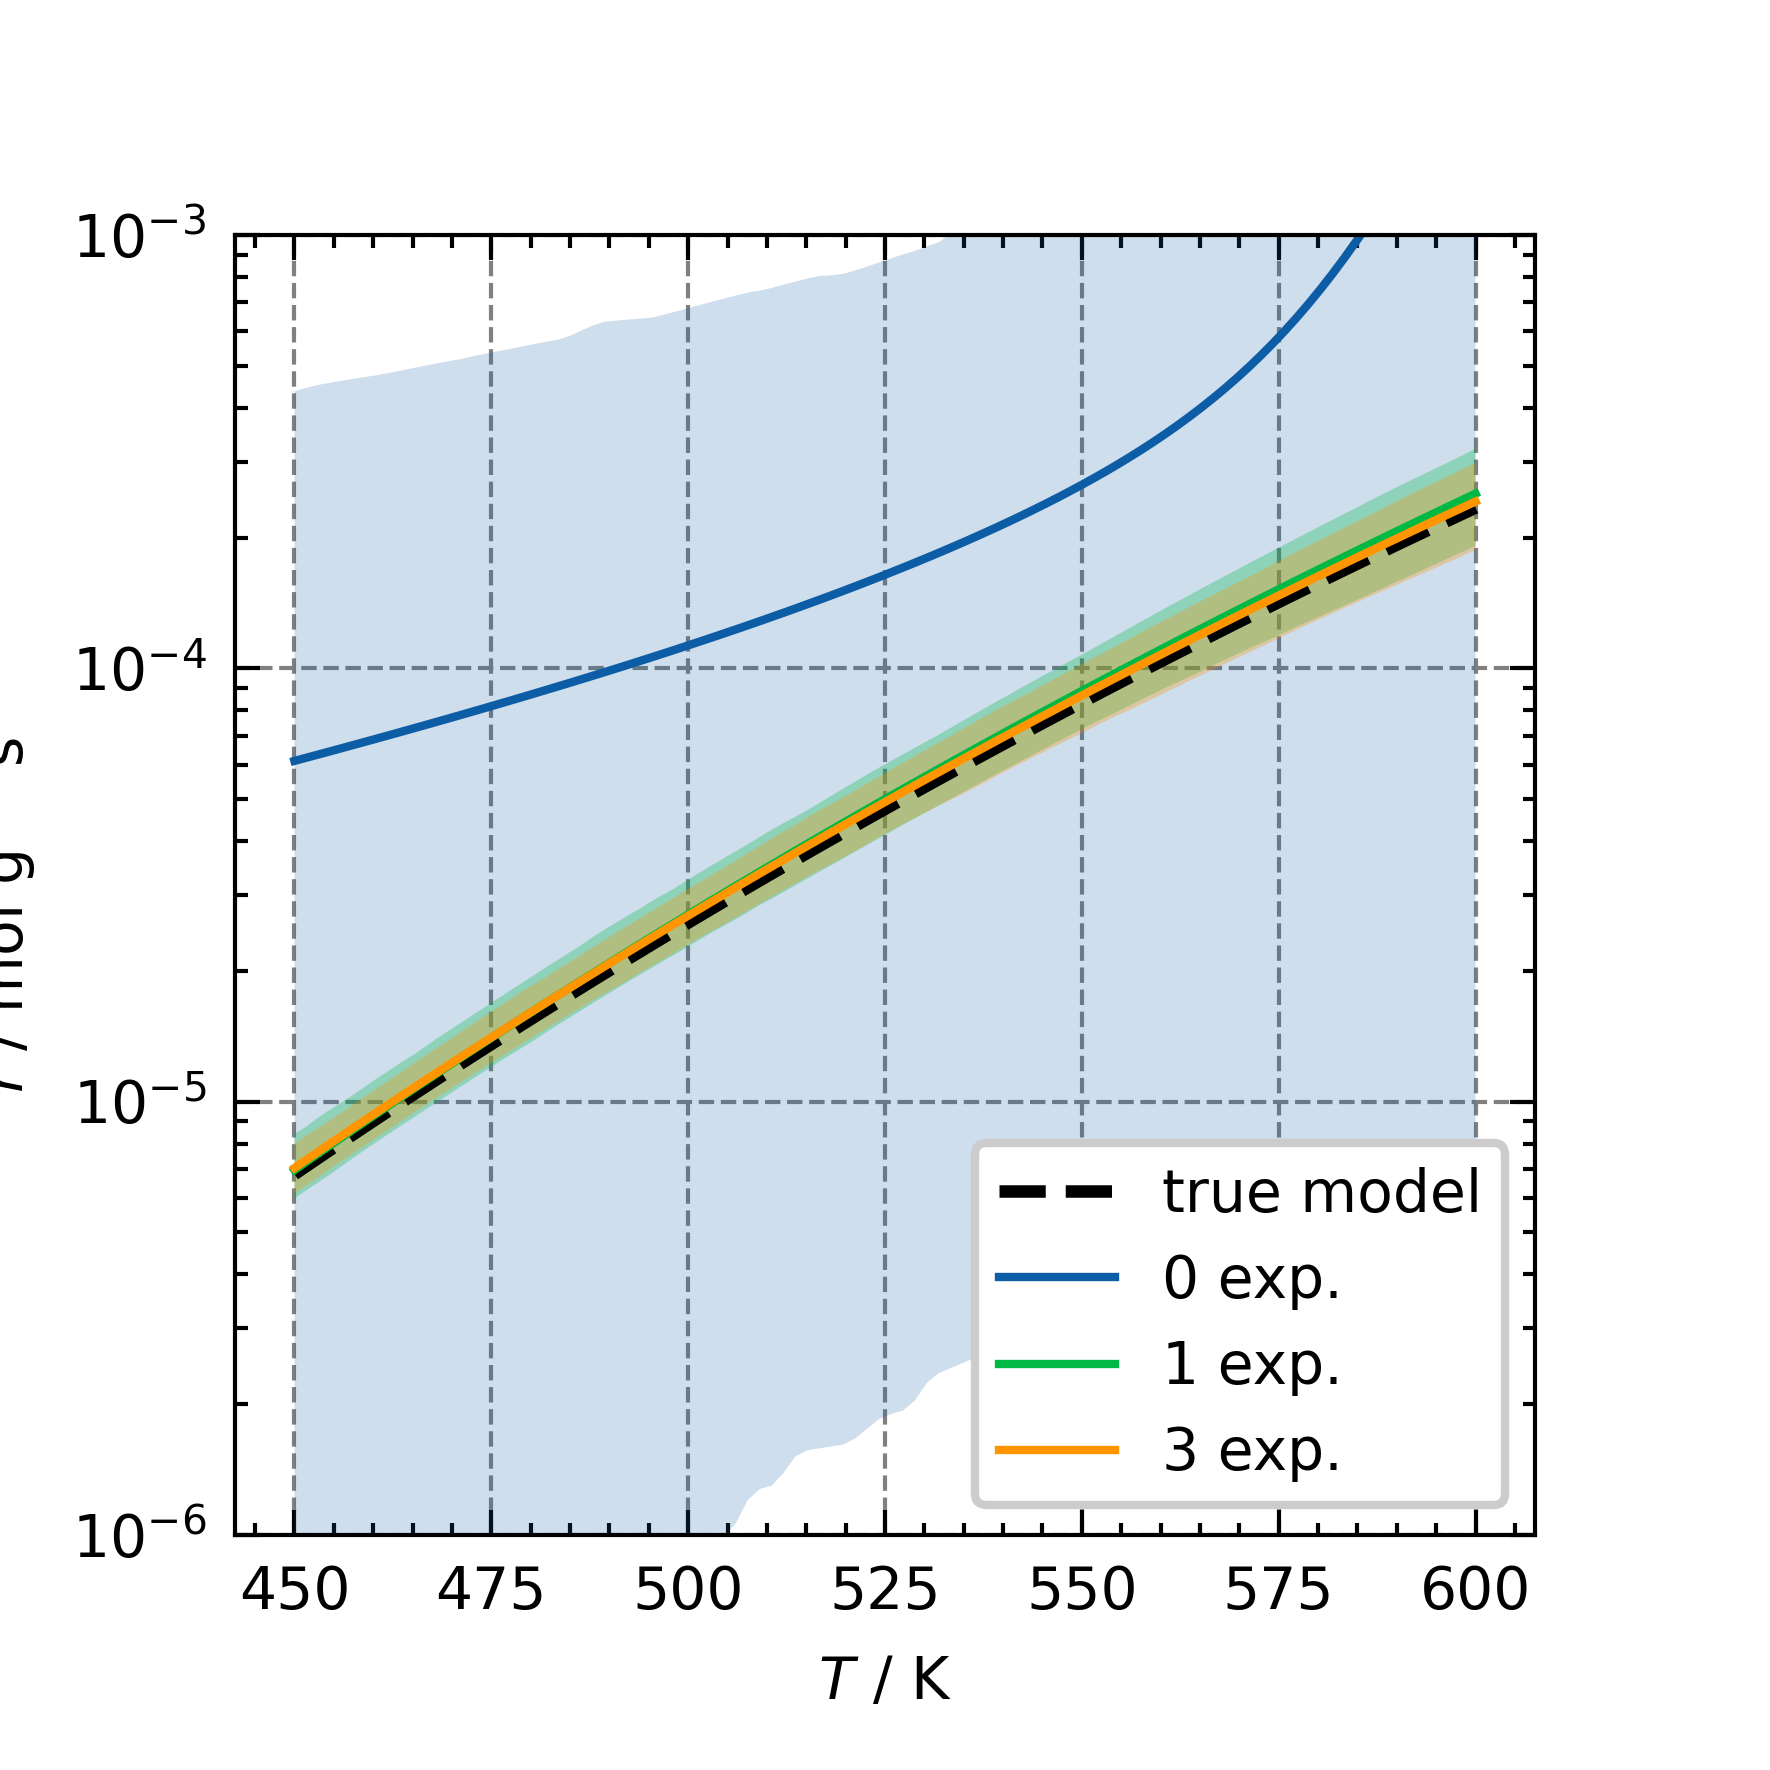

In [ ]:
j = 4
T_range = np.linspace(450, 600, 100)
fig = ICIW_Plots.figure(layout="single_column")
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="$T$ / K",
    ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
    yscale="log",
    ylim=(1e-6, 1e-3),
    # xlim=(450, 600),
)
true_res = evaluate_true_model(
    proposal=ov[-1]["proposals"][j],
)
ax.plot(
    T_range,
    true_res.squeeze(),
    label="true model",
    color="black",
    linestyle="--",
    # linewidth=2,
)
# i=0
test_res = evaluate_conditions(
    proposal=ov[-1]["proposals"][j],
    idata=ov[-1]["idatas"][0],
    key="prior",
)
ax.plot(
    T_range,
    test_res.mean(axis=1),
    label="0 exp.",
    linewidth=1.0,
)
ax.fill_between(
    T_range,
    np.percentile(test_res, 2.5, axis=1),
    np.percentile(test_res, 97.5, axis=1),
    alpha=0.2,
)
# i=1
test_res = evaluate_conditions(
    proposal=ov[-1]["proposals"][j],
    idata=ov[-1]["idatas"][1],
    key="posterior",
)
ax.plot(
    T_range,
    test_res.mean(axis=1),
    label="1 exp.",
    linewidth=1.0,
)
ax.fill_between(
    T_range,
    np.percentile(test_res, 2.5, axis=1),
    np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
)
# i=3
test_res = evaluate_conditions(
    proposal=ov[-1]["proposals"][j],
    idata=ov[-1]["idatas"][3],
    key="posterior",
)
ax.plot(
    T_range,
    test_res.mean(axis=1),
    label="3 exp.",
    linewidth=1.0,
    # color="firebrick",
)
ax.fill_between(
    T_range,
    np.percentile(test_res, 2.5, axis=1),
    np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    # facecolor="firebrick",
)
plt.legend(loc="lower right", frameon=True)
plt.savefig("B_035_Predictions.png", dpi=600, bbox_inches="tight")

### Parameter identified

In [ ]:
from ipywidgets import interact, Dropdown

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}


@interact(
    key=Dropdown(
        options=keydict.keys(),
        value="k0",
        description="Parameter:",
    ),
)
def plot_parameter_evolution(key):
    fig = ICIW_Plots.figure()
    ax = ICIW_Plots.make_square_ax(
        fig,
        ax_width=5.5 * ICIW_Plots.cm2inch,
        xlabel="number of experiments / 1",
        ylabel=f"{keydict[key]} / units",
        yscale="log",
        # ylim=(6e-7, 1e-4),
        # xlim=(-1, 67),
        xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
        left_h=1.5 * ICIW_Plots.cm2inch,
    )
    # ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    for i, ov_dict in enumerate(ov):
        param_samples = []
        for idata in ov_dict["idatas"]:
            samples = idata.posterior[key].values.flatten()
            param_samples.append(samples)
        param_samples = np.array(param_samples)
        ax.axhline(
            y=TRUE_PARAMS[keydict[key]],
            color="gray",
            linestyle="dashed",
            zorder=0,
        )
        if ov_dict["DOE"] == "Koschany DOE":
            ax.hlines(
                np.mean(param_samples, axis=1)[-1],
                xmin=-1,
                xmax=64,
                label=ov_dict["DOE"],
                ls="--",
                color=colors[i],
            )
            HDI = az.hdi(param_samples[-1], hdi_prob=0.95)
            ax.fill_between(
                np.arange(-1, len(param_samples) + 1),
                HDI[0],
                HDI[1],
                alpha=0.2,
                # ls="--",
                facecolor=colors[i],
                # edgecolor="gray",
            )
            continue
        ax.plot(
            np.arange(1, len(param_samples) + 1),
            np.mean(param_samples, axis=1),
            label=ov_dict["DOE"],
            color=plt.rcParams["axes.prop_cycle"].by_key()["color"][i],
        )
        HDI = az.hdi(param_samples.T, hdi_prob=0.95)
        ax.fill_between(
            np.arange(1, len(param_samples) + 1),
            HDI[:, 0],
            HDI[:, 1],
            alpha=0.2,
            facecolor=plt.rcParams["axes.prop_cycle"].by_key()["color"][i],
        )
        ax.legend(frameon=True)

interactive(children=(Dropdown(description='Parameter:', options=('k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h…

/tmp/ipykernel_13292/3337599411.py:74: FutureWarning:

hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions



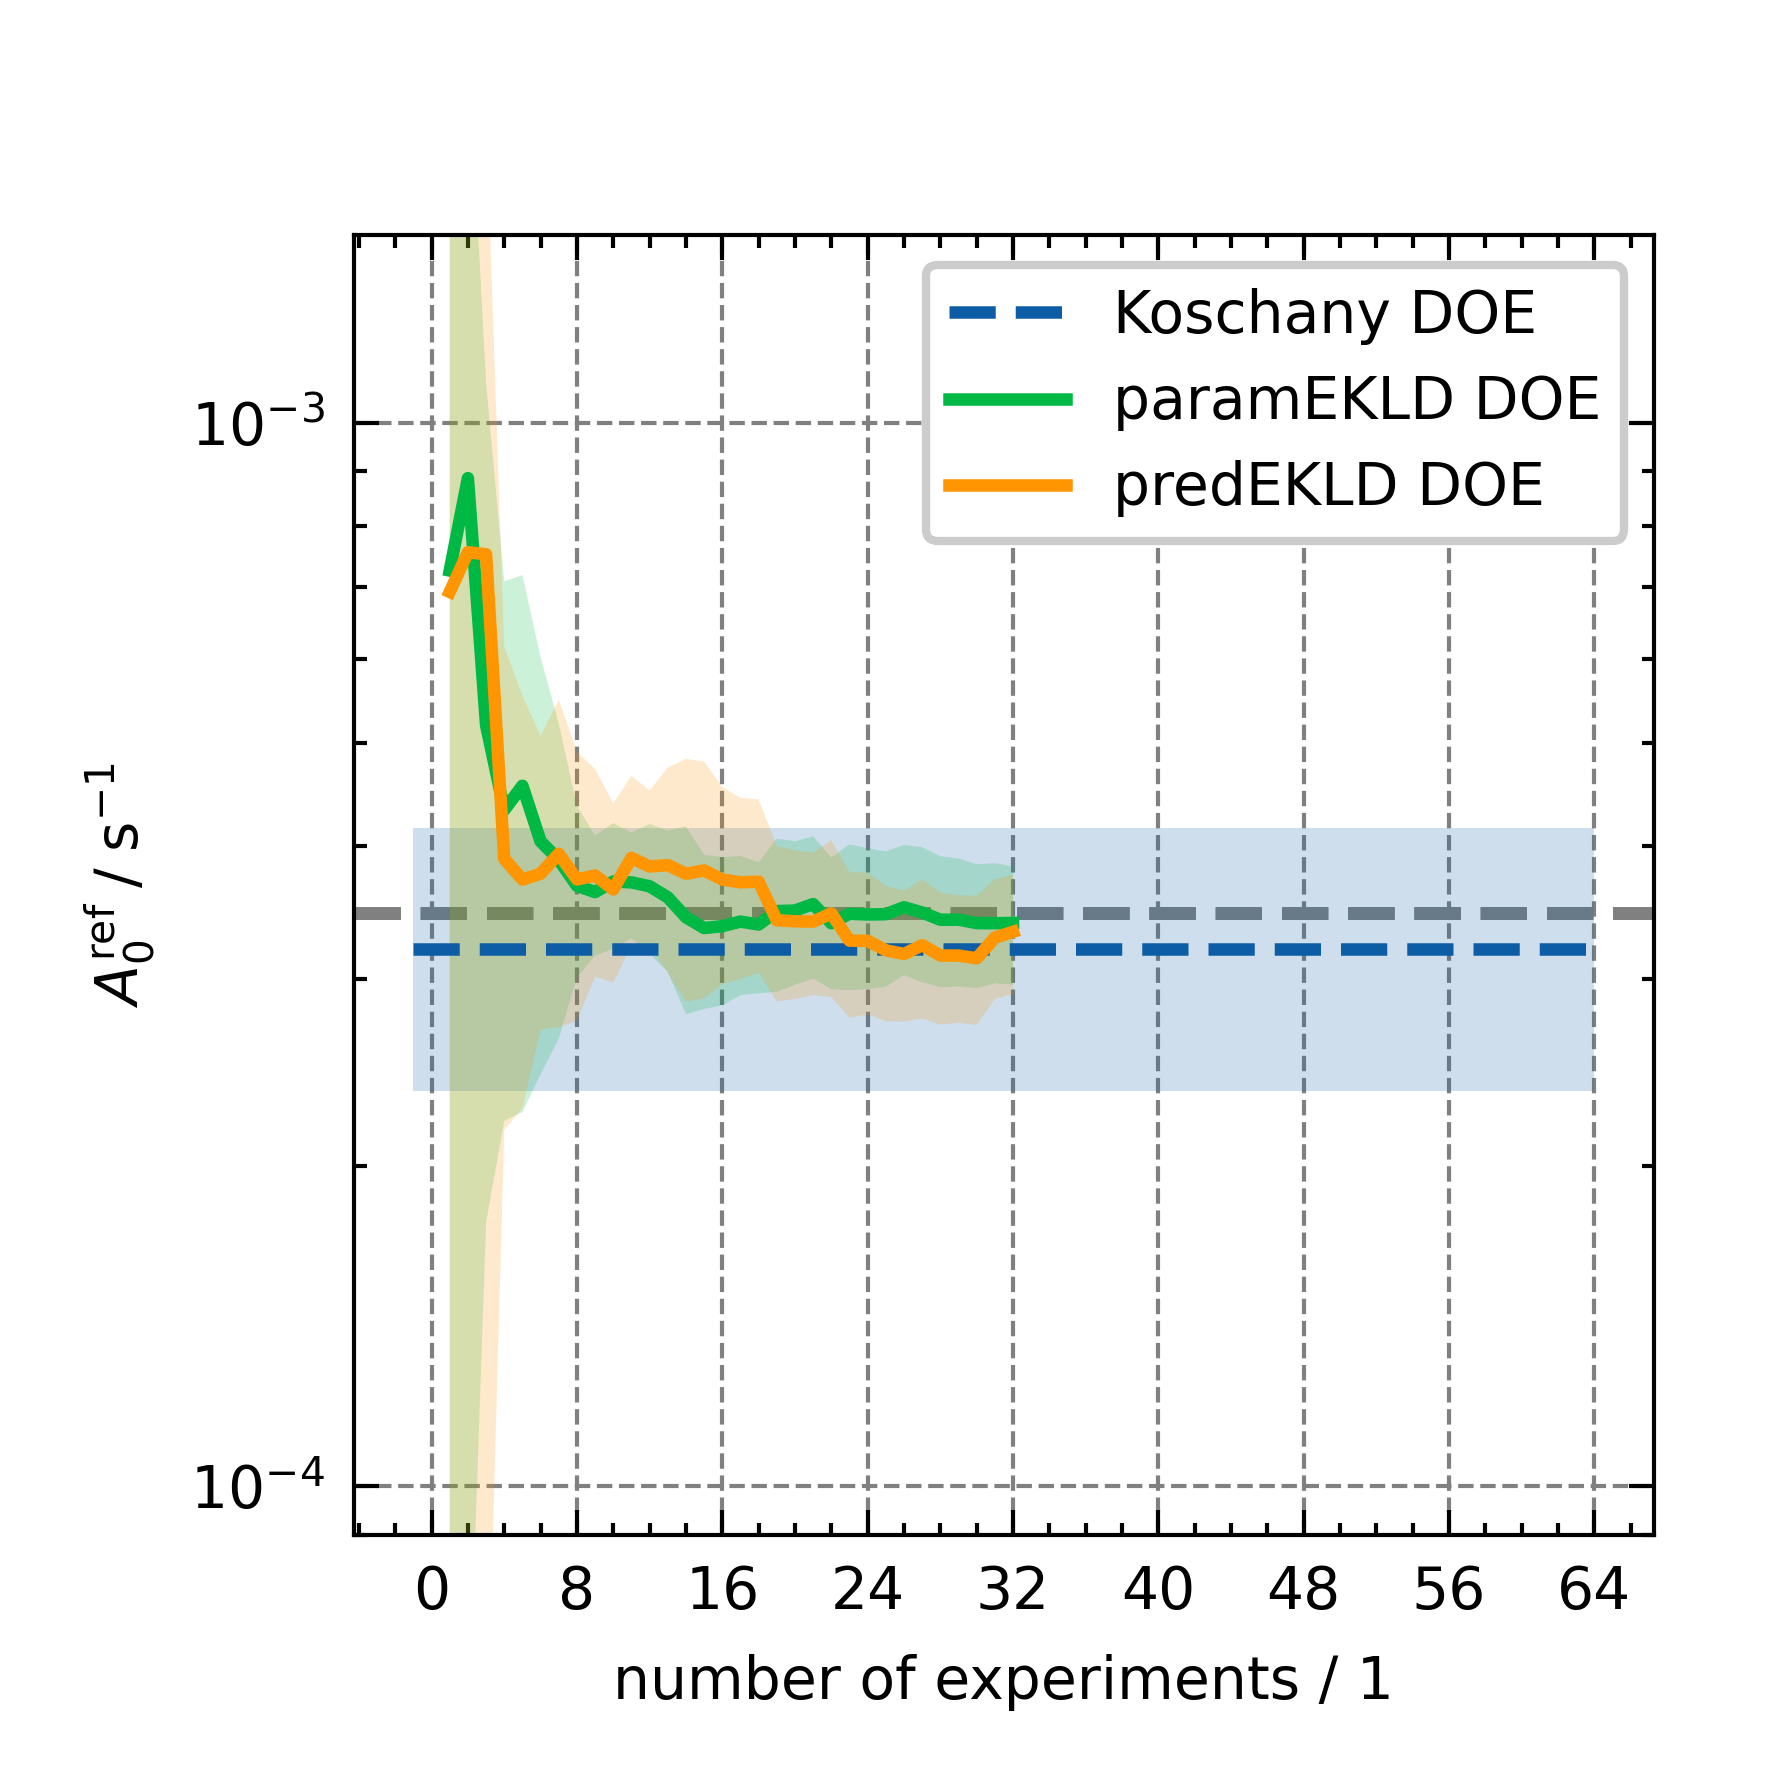

In [ ]:
plot_parameter_evolution("k0")
ax = plt.gca()
ax.set_ylabel(r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$")
ax.set_ylim(9e-5, 1.5e-3)
plt.savefig("figures/KinFit_k0_evolution.png")
plt.savefig("figures/KinFit_k0_evolution.pdf")
plt.savefig("figures/KinFit_k0_evolution.svg")

In [ ]:
import pandas as pd

# Calculate and print HDI for all parameters across all three DOEs

pd.set_option("display.float_format", lambda x: "%.3e" % x)

param_names = ["k0", "Ea_k", "A_oh", "dH_oh", "A_h2", "dH_h2", "A_mix", "dH_mix"]

results = []

for param in param_names:
    for ov_dict in ov:
        # Get final posterior samples for this parameter
        samples = ov_dict["idatas"][-1].posterior[param].values.flatten()

        # Calculate HDI
        hdi = az.hdi(samples, hdi_prob=0.95)
        mean_val = np.mean(samples)

        results.append(
            {
                "Parameter": param,
                "DOE": ov_dict["DOE"],
                "Mean": mean_val,
                "HDI_lower": hdi[0],
                "HDI_upper": hdi[1],
                "True_value": TRUE_PARAMS[keydict[param]],
            }
        )

# Create DataFrame and display
df_results = pd.DataFrame(results)

# Print results grouped by parameter
for param in ["k0"]:
    print("=" * 80)
    print(f"Parameter: {param}")
    print("-" * 80)
    param_df = df_results[df_results["Parameter"] == param]
    print(
        param_df[["DOE", "Mean", "HDI_lower", "HDI_upper", "True_value"]].to_string(
            index=False
        )
    )
    print()

Parameter: k0
--------------------------------------------------------------------------------
          DOE      Mean  HDI_lower  HDI_upper True_value
 Koschany DOE 3.199e-04  2.351e-04  4.159e-04   0.000346
paramEKLD DOE 3.385e-04  2.960e-04  3.826e-04   0.000346
 predEKLD DOE 3.320e-04  2.902e-04  3.758e-04   0.000346

